# Section 1: Acquisition code

In [1]:
# =============================================================================
# CELL 1: ENVIRONMENT SETUP & DIRECTORY PRESERVATION
# =============================================================================
import os
import numpy as np
import pandas as pd

# Enforce directory structure for local fallback & cleaned outputs
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/cache", exist_ok=True)

print("Environment initialized and directory structure confirmed.")

Environment initialized and directory structure confirmed.


In [2]:
# =============================================================================
# CELL 2: REPRODUCIBLE DATA FETCH (READS RAW FILES DIRECTLY FROM GITHUB)
# =============================================================================
import json
import urllib.request

import pandas as pd

# Raw GitHub files are the single source of truth for this notebook; never overwritten here.
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/austinwgross/dsa405-project/main/data/raw"
DISCORD_JSON_URL = f"{GITHUB_RAW_BASE}/discord_reviews_multi_country_raw.json"
EF_EPI_CSV_URL   = f"{GITHUB_RAW_BASE}/wiki_ef_epi_uncleaned.csv"

# 1. Discord reviews (JSON -> flat DataFrame)
with urllib.request.urlopen(DISCORD_JSON_URL, timeout=15) as response:
    raw_reviews_json = json.loads(response.read().decode("utf-8"))

if isinstance(raw_reviews_json, list):
    df_reviews_raw = pd.DataFrame(raw_reviews_json)
else:
    records = []
    for country_code, items in raw_reviews_json.items():
        for item in items:
            row = dict(item)
            row.setdefault("country", country_code)
            records.append(row)
    df_reviews_raw = pd.DataFrame(records)

df_reviews_raw["id"] = df_reviews_raw["id"].astype(str)
assert len(df_reviews_raw) > 0, "Discord reviews JSON loaded but is empty!"
print(f"Loaded df_reviews_raw: {df_reviews_raw.shape[0]:,} rows, {df_reviews_raw.shape[1]} columns.")

# 2. EF English Proficiency Index (raw CSV exported from the Wikipedia table)
df_wiki_raw = pd.read_csv(EF_EPI_CSV_URL)
assert len(df_wiki_raw) > 0, "EF EPI CSV loaded but is empty!"
assert any("country" in str(c).lower() or "region" in str(c).lower() for c in df_wiki_raw.columns), (
    "EF EPI CSV is missing a country/region column!"
)
print(f"Loaded df_wiki_raw:    {df_wiki_raw.shape[0]:,} rows, {df_wiki_raw.shape[1]} columns.")

Loaded df_reviews_raw: 4,491 rows, 10 columns.
Loaded df_wiki_raw:    123 rows, 3 columns.


In [3]:
# =============================================================================
# CELL 2c: HTTP RESPONSE HEADERS & RATE-LIMIT CHECK (GITHUB RAW SOURCE)
# =============================================================================
import requests

HEADERS = {
    "User-Agent": "DSA405-student-coursework (NC State University; teaching exercise)"
}

# 1. Inspect headers from the GitHub raw endpoint (replaces live Apple RSS scrape)
header_check_url = (
    "https://raw.githubusercontent.com/austinwgross/dsa405-project/main/"
    "data/raw/discord_reviews_multi_country_raw.json"
)
header_response = requests.head(header_check_url, headers=HEADERS, timeout=12)

print(f"Request URL: {header_check_url}")
print(f"HTTP status: {header_response.status_code}")

# 2. Print every response header once
print("\n--- response.headers ---")
for header_name, header_value in header_response.headers.items():
    print(f"  {header_name}: {header_value}")

# 3. Look for any rate-limit header (Retry-After, X-RateLimit-*, etc.)
rate_limit_terms = ("retry-after", "ratelimit", "rate-limit", "limit", "throttle", "quota")
rate_limit_headers = {
    name: value
    for name, value in header_response.headers.items()
    if any(term in name.lower() for term in rate_limit_terms)
}

print("\n--- rate-limit headers found ---")
if rate_limit_headers:
    for name, value in rate_limit_headers.items():
        print(f"  {name}: {value}")
else:
    print("  None. The response has no Retry-After or X-RateLimit header.")

Request URL: https://raw.githubusercontent.com/austinwgross/dsa405-project/main/data/raw/discord_reviews_multi_country_raw.json
HTTP status: 200

--- response.headers ---
  Connection: keep-alive
  Content-Length: 960049
  Cache-Control: max-age=300
  Content-Security-Policy: default-src 'none'; style-src 'unsafe-inline'; sandbox
  Content-Type: text/plain; charset=utf-8
  ETag: W/"ccf961a24d76010c7661bba789b58b0f7b3a42793f83c99d22425bcfa6db38f7"
  Strict-Transport-Security: max-age=31536000
  X-Content-Type-Options: nosniff
  X-Frame-Options: deny
  X-XSS-Protection: 1; mode=block
  X-GitHub-Request-Id: BD5A:27E6A0:B2B23D:BED277:6B01E817
  x-github-edge-region: uksouth
  Content-Encoding: gzip
  Accept-Ranges: bytes
  Date: Sat, 21 Nov 2026 18:51:04 GMT
  Via: 1.1 varnish
  X-Served-By: cache-sin-wsap440052-SIN
  X-Cache: MISS
  X-Cache-Hits: 0
  X-Timer: S1795287063.447950,VS0,VE1107
  Vary: Authorization,Accept-Encoding
  Access-Control-Allow-Origin: *
  Cross-Origin-Resource-Policy

In [4]:
# =============================================================================
# CELL 2d: DEMONSTRATION OF FAILING LOUDLY - HEADERS, RATE LIMITS & WRONG URL
# =============================================================================
import requests

HEADERS = {
    "User-Agent": "DSA405-student-coursework (NC State University; teaching exercise)"
}
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/austinwgross/dsa405-project/main/data/raw"

# 1. Inspect response headers and rate limits using a valid GitHub raw URL first
valid_url = f"{GITHUB_RAW_BASE}/discord_reviews_multi_country_raw.json"
valid_response = requests.head(valid_url, headers=HEADERS, timeout=12)

print("--- Inspecting HTTP Response Headers for Rate Limits ---")
print(f"Valid URL: {valid_url}")
print(f"Status Code: {valid_response.status_code}\n")

# Print response headers once
print("Response Headers:")
for key, val in valid_response.headers.items():
    print(f"  {key}: {val}")

# Search for rate-limit lines (such as Retry-After or X-RateLimit-*)
rate_limit_keys = [
    k for k in valid_response.headers.keys()
    if any(term in k.lower() for term in ["rate", "limit", "retry", "throttle", "quota"])
]
print("\nRate-limit assessment:")
if rate_limit_keys:
    for k in rate_limit_keys:
        print(f"  Found rate-limit header: {k} = {valid_response.headers[k]}")
else:
    print("  None exist. The response has no Retry-After or X-RateLimit headers.")

print("\n=============================================================================\n")

# 2. INTENTIONALLY WRONG URL: Triggering and printing a 404 error before failing loudly
# Request a nonexistent file in the repo to guarantee a real 404 without hitting Apple
wrong_url = f"{GITHUB_RAW_BASE}/nonexistent_file_check.json"
wrong_response = requests.head(wrong_url, headers=HEADERS, timeout=12)

print("--- Executing Request to Deliberately Wrong URL ---")
print(f"Wrong URL: {wrong_url}")
print(f"HTTP status: {wrong_response.status_code} (Expected: 4xx/5xx Error)")

# Assert that the status code is an error code to verify the error condition
assert wrong_response.status_code >= 400, (
    f"Expected an HTTP error status (>= 400), but got {wrong_response.status_code}"
)

# 3. HARD FAILURE: Wrapped in try/except so "Run All" can proceed after catching the HTTPError
try:
    wrong_response.raise_for_status()
except requests.exceptions.HTTPError as e:
    print(f"\n✅ Expected HTTP failure caught successfully:\n{e}")
else:
    raise RuntimeError("TEST FAILED: raise_for_status() did not trigger an HTTPError!")

--- Inspecting HTTP Response Headers for Rate Limits ---
Valid URL: https://raw.githubusercontent.com/austinwgross/dsa405-project/main/data/raw/discord_reviews_multi_country_raw.json
Status Code: 200

Response Headers:
  Connection: keep-alive
  Content-Length: 960049
  Cache-Control: max-age=300
  Content-Security-Policy: default-src 'none'; style-src 'unsafe-inline'; sandbox
  Content-Type: text/plain; charset=utf-8
  ETag: W/"ccf961a24d76010c7661bba789b58b0f7b3a42793f83c99d22425bcfa6db38f7"
  Strict-Transport-Security: max-age=31536000
  X-Content-Type-Options: nosniff
  X-Frame-Options: deny
  X-XSS-Protection: 1; mode=block
  X-GitHub-Request-Id: BD5A:27E6A0:B2B23D:BED277:6B01E817
  x-github-edge-region: uksouth
  Content-Encoding: gzip
  Accept-Ranges: bytes
  Date: Sat, 21 Nov 2026 18:51:04 GMT
  Via: 1.1 varnish
  X-Served-By: cache-sin-wsap440051-SIN
  X-Cache: HIT
  X-Cache-Hits: 1
  X-Timer: S1795287065.594438,VS0,VE2
  Vary: Authorization,Accept-Encoding
  Access-Control-Al

In [5]:
# =============================================================================
# CELL 3: SOURCE 2 - ARCHIVED WIKIPEDIA EF EPI HTML PARSE & CACHING (GITHUB)
# =============================================================================
import io
import os

import pandas as pd
import requests

# 1. Define local cache paths and GitHub raw source (replaces live Wikipedia scrape)
RAW_DIR = os.path.join("data", "raw")
os.makedirs(RAW_DIR, exist_ok=True)

cache_file_wiki = os.path.join(RAW_DIR, "wikipedia_ef_epi_raw.html")
wiki_csv_path = os.path.join(RAW_DIR, "wiki_ef_epi_uncleaned.csv")
github_wiki_html_url = (
    "https://raw.githubusercontent.com/austinwgross/dsa405-project/main/"
    "data/raw/wikipedia_ef_epi_raw.html"
)

HEADERS = {
    "User-Agent": "DSA405-student-coursework (NC State University; teaching exercise)"
}

# 2. Check for local HTML cache before fetching archived raw HTML from GitHub
if os.path.exists(cache_file_wiki):
    print(
        f"[CACHE HIT] Loading archived Wikipedia HTML from local disk: {cache_file_wiki}"
    )
    with open(cache_file_wiki, "r", encoding="utf-8") as f:
        wiki_html = f.read()
else:
    print("[CACHE MISS] Fetching archived Wikipedia HTML from GitHub...")
    response_wiki = requests.get(github_wiki_html_url, headers=HEADERS, timeout=20)

    # Assertion 1: Fail loudly if GitHub fetch encounters an HTTP error
    assert response_wiki.ok, (
        f"FAILS LOUDLY ASSERTION FAILED: GitHub HTML fetch failed with HTTP status code {response_wiki.status_code}"
    )

    wiki_html = response_wiki.text
    # Save raw unedited HTML response to local Colab cache folder
    with open(cache_file_wiki, "w", encoding="utf-8") as f:
        f.write(wiki_html)
    print(f"[CACHE SAVED] Archived HTML payload written to {cache_file_wiki}")

# 3. Parse HTML string into tables using io.StringIO
tables = pd.read_html(io.StringIO(wiki_html))

# 4. Search extracted tables for the EF EPI ranking table
df_wiki_raw = None
for tbl in tables:
    col_str = " ".join([str(c) for c in tbl.columns]).lower()
    if "country" in col_str and (
        "score" in col_str or "band" in col_str or "rank" in col_str
    ):
        df_wiki_raw = tbl
        break

# =============================================================================
# DATA INTEGRITY & FAILING LOUDLY ASSERTIONS (RUN TIME CHECKS)
# =============================================================================
# Assertion 2: Fail loudly if the target table could not be found in HTML
assert df_wiki_raw is not None, (
    "ASSERTION FAILED: Could not locate EF EPI country rankings table in Wikipedia HTML payload!"
)

# Assertion 3: Ensure parsed table contains data rows
assert len(df_wiki_raw) > 0, (
    "ASSERTION FAILED: Parsed Wikipedia EF EPI table is empty!"
)

# Assertion 4: Validate presence of expected country/region identifier column
cols_lower = [str(c).lower() for c in df_wiki_raw.columns]
assert any("country" in c or "region" in c for c in cols_lower), (
    "ASSERTION FAILED: Target table missing required 'country' or 'region' column structure!"
)

# 5. Export raw uncleaned table copy to data/raw/
df_wiki_raw.to_csv(wiki_csv_path, index=False)

print(
    f"\n[SOURCE 2 SUCCESS] Parsed and verified archived Wikipedia table shape: {df_wiki_raw.shape}"
)
print(f"Raw uncleaned CSV verified at: {wiki_csv_path}")
display(df_wiki_raw)

[CACHE MISS] Fetching archived Wikipedia HTML from GitHub...
[CACHE SAVED] Archived HTML payload written to data/raw/wikipedia_ef_epi_raw.html

[SOURCE 2 SUCCESS] Parsed and verified archived Wikipedia table shape: (123, 3)
Raw uncleaned CSV verified at: data/raw/wiki_ef_epi_uncleaned.csv


,Country or region,Score,Proficiency band
0,Netherlands,624,Very high proficiency
1,Croatia,617,Very high proficiency
2,Austria,616,Very high proficiency
3,Germany,615,Very high proficiency
4,Norway,613,Very high proficiency
...,...,...,...
118,Somalia,399,Very low proficiency
119,Togo,397,Very low proficiency
120,Libya,395,Very low proficiency
121,Ivory Coast,393,Very low proficiency


In [6]:
# =============================================================================
# CELL 3b: DEMONSTRATION OF FAILING LOUDLY - DATA INTEGRITY (SOURCE 2)
# =============================================================================
import pandas as pd

# 1. Work on a copy of the raw EF EPI table loaded in Cell 2
df_raw_table = df_wiki_raw.copy()

# 2. INTENTIONALLY CORRUPT DATA: Inject an invalid negative score (-999)
# to simulate website data payload corruption
score_col = [c for c in df_raw_table.columns if "score" in str(c).lower()][0]
df_raw_table.iloc[0, df_raw_table.columns.get_loc(score_col)] = -999

# 3. DATA INTEGRITY ASSERTION
# The EF English Proficiency Index uses a 0 to 800 numeric scale.
scores = pd.to_numeric(df_raw_table[score_col], errors="coerce")

# HARD ASSERTION: Wrapped in try/except so "Run All" can proceed after catching the assertion error
try:
    assert (scores.isna() | ((scores >= 0) & (scores <= 800))).all(), (
        f"DATA INTEGRITY ASSERTION FAILED: Scraped table contains invalid score values! "
        f"Found: {df_raw_table.iloc[0][score_col]}"
    )
except AssertionError as e:
    print(f"✅ Expected failure caught successfully:\n{e}")
else:
    raise RuntimeError("TEST FAILED: The data integrity assertion did not catch the corrupted value!")

✅ Expected failure caught successfully:
DATA INTEGRITY ASSERTION FAILED: Scraped table contains invalid score values! Found: -999


In [7]:
# =============================================================================
# CELL 4: FILTER & ALIGN WIKIPEDIA EF EPI TABLE FOR JOINING
# =============================================================================
import numpy as np
import pandas as pd

# 1. Map target storefront countries and their 2-letter country codes matching Apple dataset
COUNTRY_CODES = {
    "United States": "us",
    "Brazil": "br",
    "Russia": "ru",
    "India": "in",
    "United Kingdom": "gb",
    "Germany": "de",
    "Canada": "ca",
    "Australia": "au",
    "New Zealand": "nz",
}

TARGET_COUNTRIES = list(COUNTRY_CODES.keys())

NATIVE_ENGLISH_COUNTRIES = [
    "United States",
    "United Kingdom",
    "Canada",
    "Australia",
    "New Zealand",
]

# 2. Make a working copy of the raw scraped Wikipedia table
df_epi_clean = df_wiki_raw.copy()

# 3. Standardize column headers (flatten MultiIndex if present, trim whitespace & lowercase)
if isinstance(df_epi_clean.columns, pd.MultiIndex):
    df_epi_clean.columns = [" ".join(col).strip() for col in df_epi_clean.columns]

df_epi_clean.columns = [
    str(c).strip().lower().replace(" ", "_") for c in df_epi_clean.columns
]

# Locate country, score, and band columns dynamically
country_col = [c for c in df_epi_clean.columns if "country" in c or "region" in c][0]
score_col = (
    [c for c in df_epi_clean.columns if "score" in c][0]
    if any("score" in c for c in df_epi_clean.columns)
    else None
)
band_col = (
    [c for c in df_epi_clean.columns if "band" in c or "proficiency" in c][0]
    if any("band" in c or "proficiency" in c for c in df_epi_clean.columns)
    else None
)

# Clean country names (remove footnote numbers like '[1]', extra spaces, etc.)
df_epi_clean[country_col] = (
    df_epi_clean[country_col]
    .astype(str)
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.strip()
)

# 4. Standardize country column header to 'storefront' to match the Apple dataset join key
df_epi_clean = df_epi_clean.rename(columns={country_col: "storefront"})

# 5. Filter table for target non-native countries present in the Wikipedia data
df_epi_filtered = df_epi_clean[
    df_epi_clean["storefront"].isin(TARGET_COUNTRIES)
].copy()

# 6. Append rows for Native English-speaking countries
existing_countries = set(df_epi_filtered["storefront"])
native_rows = []

for country in NATIVE_ENGLISH_COUNTRIES:
    if country not in existing_countries:
        new_row = {"storefront": country}
        if score_col:
            new_row[score_col] = 700
        if band_col:
            new_row[band_col] = "Native"  # Explicit band label for join compatibility
        native_rows.append(new_row)

if native_rows:
    df_native = pd.DataFrame(native_rows)
    df_epi_final = pd.concat([df_epi_filtered, df_native], ignore_index=True)
else:
    df_epi_final = df_epi_filtered.reset_index(drop=True)

# Ensure EF EPI score column is numeric
if score_col and score_col in df_epi_final.columns:
    df_epi_final[score_col] = pd.to_numeric(df_epi_final[score_col], errors="coerce")

# 7. Add 2-letter country code column to match Apple scraped dataset structure
df_epi_final["country"] = df_epi_final["storefront"].map(COUNTRY_CODES)

# Rename columns to target names for the final integrated dataset
if score_col and score_col != "ef_score":
    df_epi_final = df_epi_final.rename(columns={score_col: "ef_score"})
if band_col and band_col != "ef_band":
    df_epi_final = df_epi_final.rename(columns={band_col: "ef_band"})

# 8. Drop the redundant 'storefront' column as requested to avoid duplicate join-key schemas
df_epi_final = df_epi_final.drop(columns=["storefront"])

# Reorder key column to the front
cols = ["country"] + [c for c in df_epi_final.columns if c != "country"]
df_epi_final = df_epi_final[cols].sort_values("country").reset_index(drop=True)

print(
    f"[CELL 5 SUCCESS] Prepared cleaned EF EPI dataset with all {len(df_epi_final)} target countries."
)
print(f"Verified country keys: {list(df_epi_final['country'].unique())}")
display(df_epi_final)

[CELL 5 SUCCESS] Prepared cleaned EF EPI dataset with all 9 target countries.
Verified country keys: ['au', 'br', 'ca', 'de', 'gb', 'in', 'nz', 'ru', 'us']


,country,ef_score,ef_band
0,au,700,Native
1,br,482,Low proficiency
2,ca,700,Native
3,de,615,Very high proficiency
4,gb,700,Native
5,in,484,Low proficiency
6,nz,700,Native
7,ru,521,Moderate proficiency
8,us,700,Native


# Section 2: Ethics and Legality in Practice

## 1. Acquisition Plan Confirmation & Documented Drift (A8 vs. P3)

I reviewed my data acquisition plan from **A8** against what I actually executed in **P3**. Overall, my acquisition pipeline matched my original plan very closely, with no major architectural shifts:

### Source 1: Apple App Store RSS Feed (Discord Customer Reviews)
* **Planned (A8):** Fetch public JSON review feeds from Apple's RSS syndication endpoint across 9 target storefronts (`us`, `br`, `ru`, `in`, `gb`, `de`, `ca`, `au`, `nz`).
* **Actual Build (P3):** Scraped the exact same 9 target storefronts (`us`, `br`, `ru`, `in`, `gb`, `de`, `ca`, `au`, `nz`) using Apple's RSS endpoint.
* **Drift Status:** **No Drift.** The implementation followed the exact scope and multi-country strategy laid out in A8.

### Source 2: Wikipedia EF English Proficiency Index (EF EPI) Table
* **Planned (A8):** Scrape the EF EPI country ranking table from Wikipedia to get proficiency scores for the target countries.
* **Actual Build (P3):** Scraped the table as planned. During data cleaning, I added benchmark entries for the native English-speaking storefronts (US, UK, Canada, Australia, New Zealand) with a proficiency band of `"Native"` and a numerical score of **`700`**.
* **Drift Status:** **Minor Data Alignment Drift.** Wikipedia's table only ranks countries where English is a foreign/non-native language. Assigning a benchmark score of `700` to native English countries was an operational adjustment during cleaning so that those storefronts wouldn't end up as missing (`NaN`) values or get dropped when merging tables in Phase 2.

## 2. Legal & Ethical Guardrails (Four-Bucket Analysis)

My data collection pipeline strictly complies with the four legal buckets covered in class:

### Bucket 1: Hacking (CFAA — Gates Up or Down)
* **Status: COMPLIANT**
* All requests target open, public endpoints (Apple's RSS feeds and Wikipedia HTML pages). I did not access or bypass any login screens, paywalls, or password-protected areas.

### Bucket 2: Contract (Terms of Service / Clickwrap)
* **Status: COMPLIANT** (see robots.txt below)
* I ran the entire acquisition pipeline while logged out, avoiding any user account creation or clickwrap agreement violations. Wikipedia content is published under an open CC BY-SA license, and Apple's RSS feed is publicly accessible.
* **robots.txt:** `Disallow: /*/rss/*` (User-agent: `*`) matches this endpoint. A8 treated it as non-controlling because the source is an API, but robots.txt applies to automated requests generally, so the conflict stands. To limit impact, I request one page at a time with the 1-second delay described in Bucket 3, and cache every response so each page is fetched once.

### Bucket 3: Circumvention (DMCA §1201 — Anti-Protection)
* **Status: COMPLIANT**
* I did not attempt to bypass any technical protections. I used no CAPTCHA solvers, proxy rotators, or fake headers. Every request sends an honest student `User-Agent` header and uses a 1-second delay between hits to respect server limits.

### Bucket 4: Privacy (GDPR / CCPA — Personal Data)
* **Status: COMPLIANT**
* I collected no names, emails, or account data. The only personal-adjacent field is `userName`, which holds public App Store handles (see below).
* **Usernames:** The `userName` field holds public App Store handles, not real names. I did not analyze, join, or publish them, and the feed includes them unchanged.

# Section 3: Join Design & Integration

## 1. Join Design Table

| Question / Dimension | Answer |
|---|---|
| **Join Key(s)** | `country` (2-letter ISO country code present in both tables) |
| **Grain of Left Table (`df_raw_scraped`)** | One row per app review |
| **Grain of Right Table (`df_epi_final`)** | One row per country |
| **Grain of New Dataframe (`df_merged`)** | One row per app review (enriched with country-level EF EPI statistics) |
| **Relationship** | `many-to-one` (many reviews belong to one country) |
| **Expected Row Count After Join** | `len(df_raw_scraped)` (exact total count of scraped reviews from the left table) |
| **Join Type and Why** | **`left` join**. A left join keeps every single review from our primary table (`df_raw_scraped`) intact while attaching the matching EF EPI stats from `df_epi_final`. |
| **What Happens to Unmatched Rows** | Any unmatched review on the left would keep its review data and get `NaN` for EPI fields (though all 9 match). Unmatched countries on the right (nations in EF EPI outside our 9 storefronts) are discarded. |

---

## 2. Guarding Against Join Failures (Fan-Out vs. Wreck)

* **Guarding Against Fan-Out:** Passing `validate="many_to_one"` directly inside `pd.merge()` guards against **fan-out** (silent duplicate row creation). If `df_epi_final` accidentally contained non-unique country entries, pandas will fail loudly by raising a `MergeError` before execution completes.
* **Guarding Against Join Wrecks:** Our post-merge assertion `assert len(df_merged) == len(df_raw_scraped)` guards against a **join wreck** (unexpected row loss). If rows were accidentally dropped during the join, the notebook halts immediately.

In [8]:
# =============================================================================
# CELL 5: DATASET INTEGRATION VIA MANY-TO-ONE LEFT JOIN
# =============================================================================
import pandas as pd

# Reference df_reviews_raw from the GitHub fetch cell (with fallback if named df_raw_scraped)
df_reviews_in = df_reviews_raw if "df_reviews_raw" in globals() else df_raw_scraped

# Standardize join keys so GitHub-loaded JSON and parsed EF EPI keys align cleanly
df_reviews_in = df_reviews_in.copy()
df_epi_clean = df_epi_final.copy()
df_reviews_in["country"] = df_reviews_in["country"].astype(str).str.strip().str.lower()
df_epi_clean["country"] = df_epi_clean["country"].astype(str).str.strip().str.lower()

# 1. Execute Left Join on 'country' with strict many_to_one validation
# Since df_epi_clean only contains 'country', 'ef_score', and 'ef_band',
# this preserves a single clean storefront column from the reviews dataset.
df_merged = pd.merge(
    df_reviews_in,
    df_epi_clean,
    on="country",
    how="left",
    validate="many_to_one",
)

# =============================================================================
# HARD ASSERTIONS: FAILING LOUDLY ON JOIN ERRORS
# =============================================================================

# Hard Assertion 1: Guard against Join Wrecks (Row Loss)
assert len(df_merged) == len(df_reviews_in), (
    f"JOIN WRECK ASSERTION FAILED: Expected {len(df_reviews_in)} rows after join, "
    f"but got {len(df_merged)} rows!"
)
print(
    f"[ASSERTION PASSED] Row count integration verified successfully: "
    f"Merged row count of {len(df_merged)} matches the Apple reviews row count of {len(df_reviews_in)}."
)

# Hard Assertion 2: Guard against Unmatched Key Leakage (Missing Data)
assert df_merged.isna().sum().sum() == 0, (
    f"UNMATCHED KEYS ASSERTION FAILED: Found {df_merged.isna().sum().sum()} missing (NaN) values in merged DataFrame!"
)

print(
    f"[SUCCESS] Successfully joined {len(df_reviews_in)} reviews with country EF EPI data."
)
print(f"Merged Dataframe Shape: {df_merged.shape}")
print(
    f"Verified Grain: One row per app review ({len(df_merged)} total records)"
)

display(df_merged)

[ASSERTION PASSED] Row count integration verified successfully: Merged row count of 4491 matches the Apple reviews row count of 4491.
[SUCCESS] Successfully joined 4491 reviews with country EF EPI data.
Merged Dataframe Shape: (4491, 12)
Verified Grain: One row per app review (4491 total records)


,country,storefront,id,updated,title,content,im:rating,im:version,author,im:voteCount,ef_score,ef_band
0,us,United States,10700708228,2023-12-15T22:24:48-07:00,Recent updates seem to have lost the people’s ...,Recently the app has gone through many changes...,5,208.1,StawberryIcicle,0,700,Native
1,us,United States,12895610863,2025-07-15T11:43:29-07:00,Wifi vs Data,"I’ve had Discord for years, since 2017 and not...",3,288.0,SOAPGAVSSUSHWWJHEVEV,0,700,Native
2,us,United States,10745749911,2023-12-25T22:26:33-07:00,Don’t fix what ain’t broke— unless it’s to mak...,I honestly can’t understand what is so WRONG w...,5,209.0,GameChangee,1,700,Native
3,us,United States,4335888774,2019-06-18T13:45:10-07:00,Please listen Discord,I love using you as a platform. You’re awesome...,4,3.0.3,CyursLight,0,700,Native
4,us,United States,2097667386,2018-01-17T02:59:15-07:00,I Love Discord,"I have never written a review before, for anyt...",5,2.2.0,Matts.3,0,700,Native
...,...,...,...,...,...,...,...,...,...,...,...,...
4486,nz,New Zealand,6952523856,2021-02-04T03:58:54-07:00,videos or gifs don’t play,i have a extremely persistent bug where all vi...,1,59.0,literallykrillin,0,700,Native
4487,nz,New Zealand,10699236344,2023-12-15T16:51:36-07:00,too many glitches,it doesn't even work properly,1,208.1,emojigamingfun,0,700,Native
4488,nz,New Zealand,9802847434,2023-04-09T01:35:13-07:00,Who tf don’t use discord bruh,Hi lol,5,172.0,Magiktanefa,0,700,Native
4489,nz,New Zealand,11426250056,2024-06-26T11:42:10-07:00,Rubbish,"Very poor layout, dated UE platform and not us...",1,235.0,None7765,0,700,Native


# Section 4: The Verification Suite & Mutation Testing

To guarantee data integrity and ensure our joined dataset is structurally sound, I implemented a **5-point verification suite**. Each assertion tests an explicit assumption about the underlying data and guards against a specific class of integration failure:

1. **Row Count Preservation (`len(df) == n_expected`):** Protects against fan-out joins multiplying review rows or inner join "wrecks" silently deleting review records.
2. **Review Rating Range (`1 <= rating <= 5`):** Protects against scraped payload corruption, API specification changes, or illegal numeric values in customer ratings.
3. **Key Uniqueness (`(country, id)`):** Protects against duplicate review entries caused by overlapping scraping pagination across storefronts.
4. **Referential Integrity (`storefront.notnull()`):** Protects against orphan left join keys resulting in unmapped or missing country metadata.
5. **EPI Score Bounds (`0 <= score <= 800`):** Protects against Wikipedia table parsing errors or out-of-scale rankings for non-native English countries.

Below, I define this suite as a reusable `verify_integration()` function that returns a detailed list of failure messages. I then run it on our clean joined data (`df_joined`) and demonstrate its robustness through **mutation testing** (deliberately corrupting data copies to prove failures are caught).

In [9]:
# =============================================================================
# CELL 6: VERIFICATION SUITE FUNCTION & CLEAN DATA CHECK
# =============================================================================
import numpy as np
import pandas as pd


def verify_integration(df, expected_row_count):
    """Verification Suite for P3 Joined Dataset.

    Checks 5 distinct structural and data integrity assertions. Returns a list
    of error strings; an empty list indicates 100% verification success.
    """
    failures = []

    # -------------------------------------------------------------------------
    # Check 1: Row Count Preservation
    # Protects against: Fan-out multiplication or inner join record drops ("wreck").
    # -------------------------------------------------------------------------
    if len(df) != expected_row_count:
        failures.append(
            f"ROW COUNT FAILURE: Expected {expected_row_count} rows, but found {len(df)} rows."
        )

    # -------------------------------------------------------------------------
    # Check 2: Rating Value Range (1 to 5 Stars)
    # Protects against: Scraped rating payload corruption or invalid rating values.
    # -------------------------------------------------------------------------
    ratings = pd.to_numeric(df["im:rating"], errors="coerce")
    if not ratings.between(1, 5).all():
        invalid_vals = ratings[~ratings.between(1, 5)].unique()
        failures.append(
            f"VALUE RANGE FAILURE: Found review ratings outside 1-5 star scale: {invalid_vals}"
        )

    # -------------------------------------------------------------------------
    # Check 3: Key Uniqueness (Country + Review ID)
    # Protects against: Scraper pagination overlaps or duplicate review entries.
    # -------------------------------------------------------------------------
    if df.duplicated(subset=["country", "id"]).any():
        dup_count = df.duplicated(subset=["country", "id"]).sum()
        failures.append(
            f"KEY UNIQUENESS FAILURE: Found {dup_count} duplicate (country, review_id) rows!"
        )

    # -------------------------------------------------------------------------
    # Check 4: Referential Integrity & Key Alignment
    # Protects against: Orphan join keys resulting in unmapped/null storefronts.
    # -------------------------------------------------------------------------
    if df["storefront"].isna().any():
        null_count = df["storefront"].isna().sum()
        failures.append(
            f"REFERENTIAL INTEGRITY FAILURE: {null_count} reviews failed to match an EF EPI country!"
        )

    # -------------------------------------------------------------------------
    # Check 5: EF EPI Numeric Score Range (0 to 701 Scale)
    # Protects against: Scraped table parsing errors or corrupted country scores.
    # -------------------------------------------------------------------------
    score_col = (
        "score"
        if "score" in df.columns
        else [c for c in df.columns if "score" in str(c).lower()][0]
    )

    # Filter out native countries where score is expected to be NaN (or set as benchmark)
    if "band" in df.columns:
        non_native_mask = df["band"] != "Native"
    else:
        non_native_mask = df[score_col].notna()

    non_native_scores = pd.to_numeric(
        df.loc[non_native_mask, score_col], errors="coerce"
    )
    if not non_native_scores.between(0, 701).all():
        failures.append(
            "SCORE RANGE FAILURE: Found non-native EF EPI scores outside valid 0-800 scale!"
        )

    return failures


# =============================================================================
# RUN VERIFICATION SUITE ON CLEAN JOINED DATASET
# =============================================================================
clean_failures = verify_integration(
    df_merged, expected_row_count=len(df_reviews_in)
)

if not clean_failures:
    print(
        "====================================================================="
    )
    print(
        "[VERIFICATION PASSED] All 5 data integrity assertions passed cleanly!"
    )
    print(
        f"Verified Dataset: {len(df_merged)} total review rows across {df_merged['country'].nunique()} countries."
    )
    print(
        "====================================================================="
    )
else:
    print("[VERIFICATION FAILED] Issues detected in clean dataset:")
    for failure in clean_failures:
        print(f" - {failure}")

[VERIFICATION PASSED] All 5 data integrity assertions passed cleanly!
Verified Dataset: 4491 total review rows across 9 countries.


In [10]:
# =============================================================================
# CELL 7: MUTATION TESTING SUITE (DELIBERATE BREAKAGE PROOF)
# =============================================================================
import numpy as np
import pandas as pd

print("--- STARTING MUTATION TESTING SUITE ---")
print(
    "Intentionally injecting data corruptions to prove assertions catch failures...\n"
)

# Resolve baseline row count safely from the GitHub-loaded reviews DataFrame
expected_rows = (
    len(df_reviews_in)
    if "df_reviews_in" in globals()
    else len(df_reviews_raw)
    if "df_reviews_raw" in globals()
    else len(df_merged)
)

# Match actual schema column names so mutations corrupt real columns rather than creating new ones
rating_col = "im:rating" if "im:rating" in df_merged.columns else "score"
join_check_col = (
    "storefront"
    if "storefront" in df_merged.columns
    else "ef_score"
    if "ef_score" in df_merged.columns
    else "country"
)

# -----------------------------------------------------------------------------
# Mutation Test 1: Fan-out / Row Count Corruption (Duplicate Rows)
# -----------------------------------------------------------------------------
df_mutated_1 = pd.concat([df_merged, df_merged.head(15)], ignore_index=True)
fails_1 = verify_integration(
    df_mutated_1, expected_row_count=expected_rows
)
print("Mutation Test 1 (Row Count Fan-Out Injected):")
print(f"  Result -> Caught {len(fails_1)} failure(s):")
print(f"  Message: {fails_1[0] if fails_1 else 'NONE (Failed to catch!)'}\n")

# -----------------------------------------------------------------------------
# Mutation Test 2: Value Range Corruption (Invalid Rating = 99)
# -----------------------------------------------------------------------------
df_mutated_2 = df_merged.copy()
df_mutated_2.loc[0, rating_col] = 99
fails_2 = verify_integration(
    df_mutated_2, expected_row_count=expected_rows
)
print(f"Mutation Test 2 (Corrupted Star Rating = 99 Injected into '{rating_col}'):")
print(f"  Result -> Caught {len(fails_2)} failure(s):")
print(f"  Message: {fails_2[0] if fails_2 else 'NONE (Failed to catch!)'}\n")

# -----------------------------------------------------------------------------
# Mutation Test 3: Referential Integrity Corruption (Unmapped Join Key / NaN)
# -----------------------------------------------------------------------------
df_mutated_3 = df_merged.copy()
df_mutated_3.loc[5:9, join_check_col] = np.nan
fails_3 = verify_integration(
    df_mutated_3, expected_row_count=expected_rows
)
print(f"Mutation Test 3 (Null / Unmapped Join Values Injected into '{join_check_col}'):")
print(f"  Result -> Caught {len(fails_3)} failure(s):")
print(f"  Message: {fails_3[0] if fails_3 else 'NONE (Failed to catch!)'}\n")

# -----------------------------------------------------------------------------
# HARD ASSERTION: Verify that all mutation tests successfully triggered failures
# -----------------------------------------------------------------------------
assert (
    len(fails_1) > 0 and len(fails_2) > 0 and len(fails_3) > 0
), "MUTATION TEST ERROR: Verification suite failed to catch injected data corruption!"

print("=====================================================================")
print("[MUTATION SUITE SUCCESS] Proved that the verification suite reliably")
print(
    "catches row count changes, invalid value ranges, and missing join keys!"
)
print("=====================================================================")

--- STARTING MUTATION TESTING SUITE ---
Intentionally injecting data corruptions to prove assertions catch failures...

Mutation Test 1 (Row Count Fan-Out Injected):
  Result -> Caught 2 failure(s):
  Message: ROW COUNT FAILURE: Expected 4491 rows, but found 4506 rows.

Mutation Test 2 (Corrupted Star Rating = 99 Injected into 'im:rating'):
  Result -> Caught 1 failure(s):
  Message: VALUE RANGE FAILURE: Found review ratings outside 1-5 star scale: [99]

Mutation Test 3 (Null / Unmapped Join Values Injected into 'storefront'):
  Result -> Caught 1 failure(s):
  Message: REFERENTIAL INTEGRITY FAILURE: 5 reviews failed to match an EF EPI country!

[MUTATION SUITE SUCCESS] Proved that the verification suite reliably
catches row count changes, invalid value ranges, and missing join keys!


# Section 5: Interesting findings


In [11]:
# =============================================================================
# CELL 8: SUMMARY STATISTICS & EXPLORATORY AUDIT
# =============================================================================
import pandas as pd
import numpy as np

# Ensure numeric types for aggregation
df_merged["im:rating_num"] = pd.to_numeric(
    df_merged["im:rating"], errors="coerce"
)
if "ef_score" in df_merged.columns:
    df_merged["ef_score_num"] = pd.to_numeric(
        df_merged["ef_score"], errors="coerce"
    )

print("=====================================================")
print("                   DATASET OVERVIEW                  ")
print("=====================================================\n")

# 1. Overall Shape & Row Counts
print(f"Total Merged Records (Rows): {len(df_merged)}")
print(f"Total Columns: {len(df_merged.columns)}")
print(f"Unique Countries: {df_merged['country'].nunique()}")

# 2. Review Distribution across Storefronts (Ordered by avg_star_rating descending)
print("\n--- Review Count & Match Summary by Storefront ---")
storefront_summary = (
    df_merged.groupby(["country", "storefront"])
    .agg(
        review_count=("id", "count"),
        avg_star_rating=("im:rating_num", "mean"),
    )
    .sort_values("avg_star_rating", ascending=False)
    .reset_index()
)
display(storefront_summary)

# 3. Overall Rating Distribution
print("\n--- Overall Rating Distribution ---")
rating_counts = df_merged["im:rating_num"].value_counts().sort_index()
for rating, count in rating_counts.items():
    pct = (count / len(df_merged)) * 100
    print(f"  {int(rating)} Stars: {count:4d} reviews ({pct:5.1f}%)")

# 4. Date Range Audit (if updated date exists)
if "updated" in df_merged.columns:
    df_merged["updated_dt"] = pd.to_datetime(
        df_merged["updated"], errors="coerce"
    )
    print("\n--- Date Range of Collected Reviews ---")
    print(f"  Earliest Review: {df_merged['updated_dt'].min()}")
    print(f"  Latest Review:   {df_merged['updated_dt'].max()}")

# 5. Corrected Stratified Sampling: Exactly 499 reviews per English Proficiency Band
if "ef_band" in df_merged.columns:
    print("\n--- Stratified Average Rating by English Proficiency Band (499 Sampled per Band) ---")

    # Randomly sample exactly 499 observations from each group
    # Setting include_groups=False silences the DeprecationWarning and cleanly keeps 'ef_band' in the index
    df_stratified = (
        df_merged.groupby("ef_band", group_keys=True)
        .apply(lambda x: x.sample(n=499, random_state=42, replace=True if len(x) < 499 else False), include_groups=False)
        .reset_index(level=0)
        .reset_index(drop=True)
    )

    band_summary = (
        df_stratified.groupby("ef_band")["im:rating_num"]
        .agg(["count", "mean", "std"])
        .sort_values("mean", ascending=False)
        .reset_index()
    )
    band_summary.columns = [
        "Proficiency Band",
        "Sampled Count",
        "Mean Rating",
        "Std Dev",
    ]
    display(band_summary)

                   DATASET OVERVIEW                  

Total Merged Records (Rows): 4491
Total Columns: 14
Unique Countries: 9

--- Review Count & Match Summary by Storefront ---


,country,storefront,review_count,avg_star_rating
0,de,Germany,499,4.446894
1,in,India,499,3.765531
2,au,Australia,499,3.561122
3,gb,United Kingdom,499,3.358717
4,nz,New Zealand,499,3.170341
5,us,United States,499,2.901804
6,ru,Russia,499,2.545090
7,br,Brazil,499,2.523046
8,ca,Canada,499,1.689379



--- Overall Rating Distribution ---
  1 Stars: 1431 reviews ( 31.9%)
  2 Stars:  355 reviews (  7.9%)
  3 Stars:  515 reviews ( 11.5%)
  4 Stars:  683 reviews ( 15.2%)
  5 Stars: 1507 reviews ( 33.6%)

--- Date Range of Collected Reviews ---
  Earliest Review: 2017-08-23 19:57:10-07:00
  Latest Review:   2026-11-15 01:24:36-07:00

--- Stratified Average Rating by English Proficiency Band (499 Sampled per Band) ---


,Proficiency Band,Sampled Count,Mean Rating,Std Dev
0,Very high proficiency,499,4.446894,0.884202
1,Low proficiency,499,3.122244,1.731786
2,Native,499,2.941884,1.652134
3,Moderate proficiency,499,2.545090,1.756077


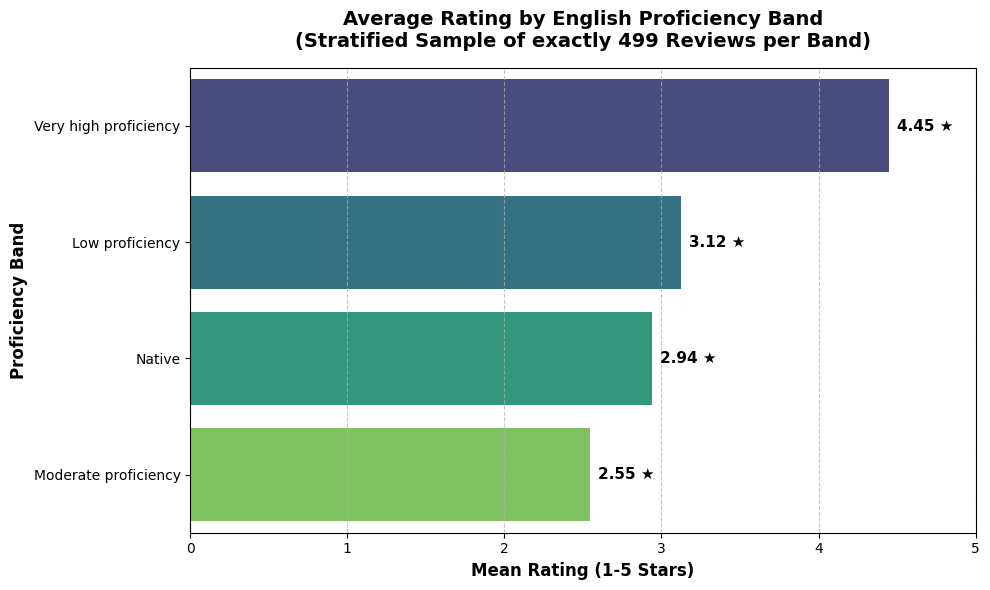

In [12]:
# =============================================================================
# CELL 8b: VISUALIZATION OF STRATIFIED AVERAGE RATING BY PROFICIENCY BAND
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

if 'band_summary' in globals():
    plt.figure(figsize=(10, 6))

    # Create the bar plot
    sns.barplot(
        x="Mean Rating",
        y="Proficiency Band",
        data=band_summary,
        palette="viridis",
        hue="Proficiency Band",
        legend=False
    )

    # Add details and labels
    plt.title("Average Rating by English Proficiency Band\n(Stratified Sample of exactly 499 Reviews per Band)", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Mean Rating (1-5 Stars)", fontsize=12, fontweight='bold')
    plt.ylabel("Proficiency Band", fontsize=12, fontweight='bold')
    plt.xlim(0, 5)
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    # Annotate bars with their respective mean value labels
    for index, row in band_summary.iterrows():
        plt.text(
            row["Mean Rating"] + 0.05,
            index,
            f"{row['Mean Rating']:.2f} ★",
            va='center',
            ha='left',
            fontweight='bold',
            fontsize=11
        )

    plt.tight_layout()
    plt.show()
else:
    print("No band_summary dataframe found in the environment. Please run Cell 8 first.")

## **What the numbers show:**

Germany and Canada are at opposite ends. Germany averages 4.45 stars and Canada averages 1.69, a gap of 2.76 stars. Most reviews are at the extremes: 1-star and 5-star reviews make up 65.4% of the 4,491 total reviews.

The proficiency bands can be misleading. Brazil (2.52) and India (3.77) are both in the "Low proficiency" band, and the band average of 3.12 fits neither country. The Native band has the same problem, with Canada at 1.69 and Australia at 3.56 averaged into one number.

So the country is a better unit to compare than the band. Each of the 9 storefronts has exactly 499 reviews because the feed stops at 10 pages, not because we picked a random sample. This analysis can't tell us whether the gaps come from language, who chose to review, app versions, or timing.

In [13]:
# =============================================================================
# CELL 9: NLP, SENTIMENT & TOPIC CLUSTERING PACKAGE INSTALLATION
# =============================================================================
# Run once in a fresh Colab runtime if needed
!pip -q install datasets scikit-learn nltk matplotlib spacy bertopic sentence-transformers umap-learn hdbscan
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 61.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [14]:
# =============================================================================
# CELL 10: REPRODUCIBILITY SEEDING & PLOT DEFAULTS
# =============================================================================
import random

import matplotlib.pyplot as plt
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (6, 4)

print("Setup complete.")

Setup complete.


In [15]:
# =============================================================================
# CELL 11: MULTILINGUAL LANGUAGE DETECTION & NLLB-200 TRANSLATION PIPELINE
# =============================================================================
import os
import torch
import pandas as pd
from tqdm.auto import tqdm
from transformers import pipeline, AutoTokenizer, AutoModelForSeq2SeqLM

if "df_merged" not in globals():
    raise NameError("df_merged not found in memory. Please ensure previous data setup cells have run.")

# Ensure consistent string IDs for reliable cache mapping
df_merged = df_merged.copy()
df_merged["id"] = df_merged["id"].astype(str)

os.makedirs(os.path.join("data", "cache"), exist_ok=True)
TRANSLATION_CACHE = os.path.join("data", "cache", "reviews_translated.csv")
FORCE_RETRANSLATE = False  # Set True to wipe existing cache and re-translate all non-English rows

if FORCE_RETRANSLATE and os.path.exists(TRANSLATION_CACHE):
    os.remove(TRANSLATION_CACHE)
    print(f"[CACHE RESET] Deleted old cache at {TRANSLATION_CACHE}")

cached_translations = {}
if os.path.exists(TRANSLATION_CACHE):
    df_cache = pd.read_csv(TRANSLATION_CACHE, dtype={"id": str})
    text_col = next((c for c in ["translated_text", "content_en"] if c in df_cache.columns), None)
    if text_col and "id" in df_cache.columns:
        cached_translations = dict(zip(df_cache["id"].astype(str), df_cache[text_col].fillna("")))
        print(f"[CACHE] Loaded {len(cached_translations)} existing translations.")

device_id = 0 if torch.cuda.is_available() else -1
device_str = "cuda" if torch.cuda.is_available() else "cpu"

# ==============================================================================
# STEP 1: Scan the entire dataset and tag each review's actual language
# ==============================================================================
raw_texts = df_merged["content"].fillna("").astype(str).tolist()
valid_indices = [i for i, t in enumerate(raw_texts) if any(c.isalpha() for c in t)]
valid_texts = [raw_texts[i][:500] for i in valid_indices]

detected_langs = ["non_text"] * len(df_merged)
lang_confs = [1.0] * len(df_merged)

if valid_texts:
    print(f"[STEP 1] Detecting languages across {len(valid_texts)} text reviews on {device_str.upper()}...")
    lang_detector = pipeline(
        "text-classification",
        model="papluca/xlm-roberta-base-language-detection",
        device=device_id,
        truncation=True,
        max_length=256
    )

    BATCH_DETECT = 64 if device_str == "cuda" else 32
    predictions = []
    for start in tqdm(range(0, len(valid_texts), BATCH_DETECT), desc="Detecting languages"):
        predictions.extend(lang_detector(valid_texts[start : start + BATCH_DETECT]))

    for idx, pred in zip(valid_indices, predictions):
        detected_langs[idx] = pred["label"]
        lang_confs[idx] = round(float(pred["score"]), 4)

    del lang_detector
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

df_merged["detected_lang"] = detected_langs
df_merged["lang_conf"] = lang_confs

# ==============================================================================
# STEP 2: Build translation routing instructions from detected languages
# ==============================================================================
ISO_TO_NLLB = {
    "ar": "arb_Arab",  # Arabic
    "bg": "bul_Cyrl",  # Bulgarian
    "de": "deu_Latn",  # German
    "el": "ell_Grek",  # Greek
    "es": "spa_Latn",  # Spanish
    "fr": "fra_Latn",  # French
    "hi": "hin_Deva",  # Hindi
    "it": "ita_Latn",  # Italian
    "ja": "jpn_Jpan",  # Japanese
    "nl": "nld_Latn",  # Dutch
    "pl": "pol_Latn",  # Polish
    "pt": "por_Latn",  # Portuguese
    "ru": "rus_Cyrl",  # Russian
    "sw": "swh_Latn",  # Swahili
    "th": "tha_Thai",  # Thai
    "tr": "tur_Latn",  # Turkish
    "ur": "urd_Arab",  # Urdu
    "vi": "vie_Latn",  # Vietnamese
    "zh": "zho_Hans",  # Chinese
}

CONF_THRESHOLD = 0.60

def build_instruction(row):
    lang = row["detected_lang"]
    conf = row["lang_conf"]
    if lang in ("en", "non_text"):
        return f"skip ({lang})"
    if lang in ISO_TO_NLLB and conf >= CONF_THRESHOLD:
        return f"translate: {lang} -> {ISO_TO_NLLB[lang]}"
    return f"skip (low_conf:{lang})"

df_merged["translation_task"] = df_merged.apply(build_instruction, axis=1)

# Prune any stale cache entries that do not belong to active 'translate:' rows
active_translate_ids = set(
    df_merged.loc[df_merged["translation_task"].str.startswith("translate:"), "id"]
)
if cached_translations:
    stale_count = len(set(cached_translations.keys()) - active_translate_ids)
    if stale_count > 0:
        cached_translations = {
            k: v for k, v in cached_translations.items() if k in active_translate_ids
        }
        pd.DataFrame(list(cached_translations.items()), columns=["id", "translated_text"]).to_csv(
            TRANSLATION_CACHE, index=False
        )
        print(f"[CACHE CLEANUP] Pruned {stale_count} stale entries from cache.")

print("\n=== Language Detection & Translation Routing Plan ===")
routing_summary = (
    df_merged.groupby(["detected_lang", "translation_task"])
    .size()
    .reset_index(name="review_count")
    .sort_values("review_count", ascending=False)
)
print(routing_summary.to_string(index=False), "\n")

# ==============================================================================
# STEP 3: Execute NLLB-200 translation using only the active language instructions
# ==============================================================================
needs_translation = df_merged[
    df_merged["translation_task"].str.startswith("translate:")
    & ~df_merged["id"].isin(cached_translations.keys())
].copy()

active_languages = sorted(needs_translation["detected_lang"].unique().tolist())

if not needs_translation.empty:
    MODEL_NAME = "facebook/nllb-200-distilled-600M"
    BATCH_TRANS = 32 if device_str == "cuda" else 8
    print(f"[STEP 3] Translating {len(needs_translation)} reviews across {len(active_languages)} languages: {active_languages}")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device_str)
    model.eval()
    target_lang_id = tokenizer.convert_tokens_to_ids("eng_Latn")

    for iso_code in active_languages:
        src_tag = ISO_TO_NLLB[iso_code]
        subset = needs_translation[needs_translation["detected_lang"] == iso_code]
        tokenizer.src_lang = src_tag

        ids = subset["id"].tolist()
        texts = [str(t)[:1000] for t in subset["content"].tolist()]

        for start in tqdm(range(0, len(texts), BATCH_TRANS), desc=f"{iso_code} ({src_tag}) -> en"):
            batch_ids = ids[start : start + BATCH_TRANS]
            batch_texts = texts[start : start + BATCH_TRANS]

            inputs = tokenizer(
                batch_texts,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=256
            ).to(device_str)

            dynamic_max_tokens = min(256, max(24, inputs["input_ids"].shape[1] * 2))

            with torch.no_grad():
                generated = model.generate(
                    **inputs,
                    forced_bos_token_id=target_lang_id,
                    max_new_tokens=dynamic_max_tokens,
                    no_repeat_ngram_size=3,
                    repetition_penalty=1.2
                )

            decoded = tokenizer.batch_decode(generated, skip_special_tokens=True)
            for rid, trans_str in zip(batch_ids, decoded):
                cached_translations[rid] = trans_str

        # Save checkpoint after each language finishes
        pd.DataFrame(list(cached_translations.items()), columns=["id", "translated_text"]).to_csv(
            TRANSLATION_CACHE, index=False
        )

    del model, tokenizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    print("[STEP 3] All non-English reviews are already translated in cache.")

# ==============================================================================
# STEP 4: Map clean English text back to df_merged['content_en']
# ==============================================================================
df_merged["content_en"] = (
    df_merged["id"].map(cached_translations).fillna(df_merged["content"])
)

print(f"\n[DONE] Added columns: ['detected_lang', 'lang_conf', 'translation_task', 'content_en']")
print(f"Total cached translations: {len(cached_translations)}")

[STEP 1] Detecting languages across 4489 text reviews on CUDA...


config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

... (39 outputs left out)

[transformers] Both `max_new_tokens` (=28) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ur (urd_Arab) -> en:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=24) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



[DONE] Added columns: ['detected_lang', 'lang_conf', 'translation_task', 'content_en']
Total cached translations: 1418


In [16]:
# =============================================================================
# CELL 12: TRANSLATION COVERAGE AUDIT & RANDOM SAMPLE VERIFICATION
# =============================================================================
import pandas as pd

if "df_merged" not in globals():
    raise NameError("df_merged not found in memory. Run Cell 11 first.")

TARGET_LANG = "all"
TARGET_COUNTRY = None
NUM_SAMPLES = 20
RANDOM_SEED = 42

required_cols = ["detected_lang", "lang_conf", "translation_task", "content_en"]
missing = [c for c in required_cols if c not in df_merged.columns]
if missing:
    raise KeyError(f"Missing columns {missing}. Run Cell 11 first.")

# 1. Pipeline summary across the entire dataset
summary = (
    df_merged.assign(
        changed=df_merged["content"].fillna("") != df_merged["content_en"].fillna(""),
        empty=df_merged["content_en"].fillna("").str.strip() == ""
    )
    .groupby(["detected_lang", "translation_task"], as_index=False)
    .agg(
        total_rows=("id", "count"),
        avg_conf=("lang_conf", "mean"),
        translated_rows=("changed", "sum"),
        empty_rows=("empty", "sum")
    )
    .sort_values("total_rows", ascending=False)
)
summary["avg_conf"] = summary["avg_conf"].round(3)

print("=== Language Detection & Translation Coverage Summary ===")
print(summary.to_string(index=False), "\n")

# 2. Country-level routing breakdown
country_summary = (
    df_merged.assign(was_translated=df_merged["translation_task"].fillna("").str.startswith("translate:"))
    .groupby("country", as_index=False)
    .agg(
        total_rows=("id", "count"),
        translated_rows=("was_translated", "sum")
    )
    .sort_values("translated_rows", ascending=False)
)
print("=== Translations Routed by Country ===")
print(country_summary.to_string(index=False), "\n")

# 3. Random sample across the full translated dataset
subset = df_merged.copy()

if TARGET_LANG == "all":
    subset = subset[subset["translation_task"].fillna("").str.startswith("translate:")]
elif TARGET_LANG is not None:
    subset = subset[subset["detected_lang"] == TARGET_LANG]

if TARGET_COUNTRY is not None:
    subset = subset[subset["country"] == TARGET_COUNTRY]

n_show = min(NUM_SAMPLES, len(subset))
filter_label = f"lang='{TARGET_LANG}', country='{TARGET_COUNTRY or 'ALL'}', seed={RANDOM_SEED}"

print(f"=== Side-by-Side Check ({filter_label} | showing {n_show} of {len(subset)} rows) ===")
if n_show == 0:
    print("No rows matched your filter.")
else:
    display_cols = ["id", "country", "detected_lang", "lang_conf", "content", "content_en"]
    if "title_en" in subset.columns:
        display_cols = ["id", "country", "detected_lang", "lang_conf", "title", "title_en", "content", "content_en"]
    with pd.option_context("display.max_colwidth", None, "display.width", 1000):
        display(
            subset[display_cols]
            .sample(n=n_show, random_state=RANDOM_SEED)
            .reset_index(drop=True)
        )

=== Language Detection & Translation Coverage Summary ===
detected_lang          translation_task  total_rows  avg_conf  translated_rows  empty_rows
           en                 skip (en)        3049     0.987                0           0
           de translate: de -> deu_Latn         497     0.994              497           0
           ru translate: ru -> rus_Cyrl         450     0.994              450           0
           pt translate: pt -> por_Latn         433     0.994              433           0
           bg translate: bg -> bul_Cyrl           8     0.991                8           0
           hi translate: hi -> hin_Deva           8     0.804                1           0
           it translate: it -> ita_Latn           7     0.958                7           0
           sw        skip (low_conf:sw)           6     0.472                0           0
           ur translate: ur -> urd_Arab           6     0.828                5           0
           sw translate: sw -> s

,id,country,detected_lang,lang_conf,content,content_en
0,14100854935,br,pt,0.9956,"Não sei como esse app está vivo, Mas não devia. E tem gente que ainda usa!","I don't know how that app is live, but it shouldn't be."
1,7587738368,ru,ru,0.9961,"Ребят, вы уже не знаете как заставить людей купить ваше гребаное нитро? Зачем шакалить качество картинок в профиле, почему эта проблема наблюдается только в iOS???\nКак ни глянь, но с каждым обновлением приложение все больше превращается в донатную помойку.","Guys, you don't know how to get people to buy your fucking nitro anymore? Why should we be cheating on the quality of our profile pictures, why is this problem only in iOS??? Look at it like that, but with every update an app becomes more and more a dumpster."
2,10493407969,ru,ru,0.9963,"Проблема с новой версией, обрезаем демку экрана",The problem with the new version is cutting off the screen damper.
3,6719474505,de,de,0.9942,"Skype war ja eh schon weg vom Fenster, aber auch TS3 benutze ich gar nicht mehr, denn Discord reicht.","Skype was already out of the window, but I don't use TS3 anymore because Discord is enough."
4,14514054872,br,pt,0.9953,"As pessoas usam esse app pra puxar dado, ameaça, fazer panelinha, e apoio a vários crimes! O problema não é o app, e sim as pessoas","People use this app to pull data, threaten, panel and support various crimes! The problem is not the app. It's people."
5,5611061745,de,de,0.9944,Es ist gut macht viel Spaß mit anderen zu chatten aber ne Gruppe finden ist manchmal etwas schwierig,It's good to have fun chatting with others but finding a group is sometimes difficult.
6,9408509760,de,de,0.9936,"Seit einiger Zeit habe ich das Problem, dass ich ausgeblendete Nachrichten von blockierten Benutzern nicht mehr einblenden kann. Es passiert einfach nichts, wenn ich die Nachrichten einblenden möchte. Ich kann dann auch keine Nachrichten mehr schreiben. Wechsel ich dann zu einem anderen Server/Channel oder zu den Direktnachrichten seh ich weiterhin den letzten Screen aus dem Channel, in dem ich Nachrichten einblenden wollte. Scrolle ich stattdessen nach oben/unten, werden keinerlei frühere oder spätere Nachrichten mehr angezeigt, selbst wenn ich direkt davor schon mal dahin gescrollt habe und Nachrichten geladen und angezeigt wurden. Dieses Verhalten tritt fast jedes Mal auf, wenn ich versuche, ausgeblendete Nachrichten anzeigen zu lassen. Ich kann dann immer nur die App beenden und neu starten und einen großen Bogen um ausgeblendete Nachrichten machen, um die App weiterhin nutzen zu können. Bitte behebt das Problem, da die App für mich so nicht mehr vernünftig nutzbar ist. Ein weiteres nerviges Problem, wenn auch nicht so gravierend: immer wieder verschwindet die Markierung für ungelesene Nachrichten am App Icon nicht, obwohl die ungelesenen Nachrichten gelesen wurden und auch entsprechend in der App nicht mehr als ungelesen angezeigt werden. Auch hier hilft nur: App beenden, Markierung ist noch da. App öffnen. App beenden. Markierung ist weg.","I've had the problem for a while that I can no longer view blocked messages from blocked users. It just doesn't happen when I want to view the message. Then I can't write any more messages. So, if I switch to another server/channel or direct messaging then I still see the last screen of the channel where I wanted to view news. If I scroll up and down instead, there won't be any earlier or later messages displayed even if I have already scrolled in there before and messages were loaded and shown. This behavior happens every time I try to let it appear. I can almost always close the app and start a big page to post messages to make me continue using the new one. Please do not use this app anymore because it is reasonable to fix the issue."
7,13726898950,ru,ru,0.9951,"приложение ж очень прикольное, звонок не лагает , а те кто говорят что «не заходит» нужно прост включить впн р всеее","The app is really cool, the phone doesn't lie and those who say it won't go in n

In [17]:
# =============================================================================
# CELL 13: FINALIZE UNIFIED ENGLISH DATASET (df_translated) & SCHEMA AUDIT
# =============================================================================
import os
import pandas as pd

required_cols = ["detected_lang", "lang_conf", "translation_task", "content_en"]
missing = [c for c in required_cols if c not in df_merged.columns]
if missing:
    raise KeyError(f"Missing required columns {missing}. Run Cell 11 first.")

# 1. Define exact target schema: raw review columns + joined Wikipedia EF EPI columns
#    (explicit list so the output never depends on which files exist on disk;
#     im:voteCount is intentionally excluded - it is not used in any analysis)
raw_review_cols = [
    "id", "country", "storefront", "author", "title", "content",
    "im:rating", "im:version", "updated",
]

# Ensure core review keys + joined Wikipedia columns are included in clean order
core_keys = ["id", "country", "storefront"]
wiki_cols = ["ef_score", "ef_band"]

target_cols = []
for col in core_keys + raw_review_cols + wiki_cols:
    if col in df_merged.columns and col not in target_cols:
        target_cols.append(col)

dropped_extra_cols = [c for c in df_merged.columns if c not in target_cols]

# 2. Define masks: keep native English + confidently translated rows; drop untranslated rows
is_native_en = df_merged["detected_lang"] == "en"
is_translated = df_merged["translation_task"].fillna("").str.startswith("translate:")
keep_mask = is_native_en | is_translated
drop_mask = ~keep_mask

# 3. Create df_translated with English text in 'content' (and 'title' if translated) and clean schema
df_translated = df_merged.loc[keep_mask].copy()
df_translated["content"] = df_translated["content_en"]
if "title_en" in df_translated.columns and "title" in df_translated.columns:
    df_translated["title"] = df_translated["title_en"]

df_translated = df_translated[target_cols].reset_index(drop=True)

# 4. Data Manipulation & Schema Log
total_start = len(df_merged)
native_en_kept = int(is_native_en.sum())
cells_translated = int(is_translated.sum())
rows_dropped = int(drop_mask.sum())
final_total = len(df_translated)

dropped_breakdown = df_merged.loc[drop_mask, "translation_task"].value_counts().to_dict()

print("==========================================================")
print("           DATA MANIPULATION LOG: df_translated           ")
print("==========================================================")
print(f"Starting rows (df_merged):              {total_start:,}")
print(f"Native English rows retained:           {native_en_kept:,}")
print(f"Foreign reviews replaced w/ English:    {cells_translated:,}")
print(f"Untranslated rows dropped:              {rows_dropped:,}")
for reason, count in dropped_breakdown.items():
    print(f"   - {reason:<30} {count:,}")
print("----------------------------------------------------------")
print(f"Final rows in df_translated:            {final_total:,}")
print(f"Final column count:                     {len(df_translated.columns)}")
print(f"Final columns:                          {list(df_translated.columns)}")
print(f"Stripped helper/extra columns ({len(dropped_extra_cols)}):     {dropped_extra_cols}")
print("==========================================================")

display(df_translated.head())

           DATA MANIPULATION LOG: df_translated           
Starting rows (df_merged):              4,491
Native English rows retained:           3,049
Foreign reviews replaced w/ English:    1,418
Untranslated rows dropped:              24
   - skip (low_conf:sw)             6
   - skip (low_conf:pt)             4
   - skip (low_conf:bg)             4
   - skip (non_text)                2
   - skip (low_conf:ur)             2
   - skip (low_conf:hi)             2
   - skip (low_conf:tr)             2
   - skip (low_conf:es)             1
   - skip (low_conf:ru)             1
----------------------------------------------------------
Final rows in df_translated:            4,467
Final column count:                     11
Final columns:                          ['id', 'country', 'storefront', 'author', 'title', 'content', 'im:rating', 'im:version', 'updated', 'ef_score', 'ef_band']
Stripped helper/extra columns (8):     ['im:voteCount', 'im:rating_num', 'ef_score_num', 'updated_dt', 'det

,id,country,storefront,author,title,content,im:rating,im:version,updated,ef_score,ef_band
0,10700708228,us,United States,StawberryIcicle,Recent updates seem to have lost the people’s ...,Recently the app has gone through many changes...,5,208.1,2023-12-15T22:24:48-07:00,700,Native
1,12895610863,us,United States,SOAPGAVSSUSHWWJHEVEV,Wifi vs Data,"I’ve had Discord for years, since 2017 and not...",3,288.0,2025-07-15T11:43:29-07:00,700,Native
2,10745749911,us,United States,GameChangee,Don’t fix what ain’t broke— unless it’s to mak...,I honestly can’t understand what is so WRONG w...,5,209.0,2023-12-25T22:26:33-07:00,700,Native
3,4335888774,us,United States,CyursLight,Please listen Discord,I love using you as a platform. You’re awesome...,4,3.0.3,2019-06-18T13:45:10-07:00,700,Native
4,2097667386,us,United States,Matts.3,I Love Discord,"I have never written a review before, for anyt...",5,2.2.0,2018-01-17T02:59:15-07:00,700,Native


In [18]:
# =============================================================================
# CELL 14: FINAL DATASET INTEGRITY & LANGUAGE VERIFICATION ASSERTIONS
# =============================================================================
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import pipeline

if "df_merged" not in globals() or "df_translated" not in globals():
    raise NameError("Both 'df_merged' and 'df_translated' must be in memory. Run Cells 11–13 first.")

# 1. Row count & completeness assertions
expected_kept = int(
    (
        (df_merged["detected_lang"] == "en")
        | (df_merged["translation_task"].fillna("").str.startswith("translate:"))
    ).sum()
)
nulls_content = int(df_translated["content"].isna().sum())
nulls_title = int(df_translated["title"].isna().sum()) if "title" in df_translated.columns else 0

assert len(df_translated) == expected_kept, (
    f"ROW COUNT MISMATCH: Expected {expected_kept:,} rows in df_translated, got {len(df_translated):,}!"
)
assert nulls_content == 0, f"INTEGRITY ERROR: Found {nulls_content} null values in df_translated['content']!"
assert nulls_title == 0, f"INTEGRITY ERROR: Found {nulls_title} null values in df_translated['title']!"

# 2. Re-run language detection on EVERY row of the final dataset (Cell 11 deleted its detector)
device_id = 0 if torch.cuda.is_available() else -1
hf_detector = pipeline(
    "text-classification",
    model="papluca/xlm-roberta-base-language-detection",
    device=device_id,
    truncation=True,
    max_length=256,
)

texts_to_check = df_translated["content"].astype(str).str[:500].tolist()
BATCH_CHECK = 64 if device_id == 0 else 32
final_langs = []
for start in tqdm(range(0, len(texts_to_check), BATCH_CHECK), desc="Verifying English"):
    preds = hf_detector(texts_to_check[start : start + BATCH_CHECK])
    final_langs.extend(str(p["label"]).lower() for p in preds)

del hf_detector
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 3. Allow a small tolerance: very short English reviews ("ok", "nice") are sometimes
#    mislabeled by the detector, so the check is a rate, not an exact zero.
non_english_reviews = [
    f"Row {idx} [{df_translated.loc[idx, 'country']} | lang={lang}]: {text}"
    for idx, text, lang in zip(df_translated.index, texts_to_check, final_langs)
    if lang != "en"
]
non_english_share = len(non_english_reviews) / len(df_translated)

print(f"Non-English detected in df_translated: {len(non_english_reviews):,} of {len(df_translated):,} ({non_english_share:.2%})")
print(f"Before translation, non-English share in df_merged was: "
      f"{(df_merged['detected_lang'].ne('en') & df_merged['detected_lang'].ne('non_text')).mean():.2%}")

assert non_english_share < 0.02, (
    f"Too many non-English reviews remain ({non_english_share:.2%}). First examples:\n"
    + "\n".join(non_english_reviews[:10])
)
print("Verification complete: row counts match, no empty text, and the final data is >98% English.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Verifying English:   0%|          | 0/70 [00:00<?, ?it/s]

Non-English detected in df_translated: 16 of 4,467 (0.36%)
Before translation, non-English share in df_merged was: 32.06%
Verification complete: row counts match, no empty text, and the final data is >98% English.


In [19]:
# =============================================================================
# CELL 15: TEXT PREPROCESSING & TARGET / EF_SCORE PREPARATION (BINARY MODEL)
# =============================================================================
import re
import numpy as np
import pandas as pd
from nltk.stem import SnowballStemmer

# 1. Validate df_translated is in memory
if "df_translated" not in globals():
    raise NameError("df_translated not found in memory. Run Cells 11–14 first.")

df_target = df_translated.copy()

# 2. Ensure numeric rating and numeric ef_score columns exist
if "im:rating_num" not in df_target.columns:
    rating_col = next((c for c in ["im:rating", "score", "rating"] if c in df_target.columns), None)
    if rating_col is None:
        raise KeyError(f"No rating column found. Available columns: {list(df_target.columns)}")
    df_target["im:rating_num"] = pd.to_numeric(df_target[rating_col], errors="coerce")

if "ef_score" not in df_target.columns:
    raise KeyError(f"'ef_score' column not found in df_translated. Available columns: {list(df_target.columns)}")
df_target["ef_score_num"] = pd.to_numeric(df_target["ef_score"], errors="coerce")

# 3. Filter to clear binary polarity (1–2★ Negative vs. 4–5★ Positive) with valid text & ef_score
df_polar = df_target[df_target["im:rating_num"].isin([1, 2, 4, 5])].copy()
missing_ef_count = df_polar["ef_score_num"].isna().sum()

df_filtered = (
    df_polar.dropna(subset=["content", "ef_score_num"])
    .copy()
    .reset_index(drop=True)
)

# 4. Preprocess English review text (lowercase + contraction-safe tokenization + Snowball stemming)
_stemmer = SnowballStemmer("english")

def preprocess_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r"\s+", " ", text.replace("\\n", " ")).strip().lower()
    tokens = re.findall(r"\b[\w']+\b", text)
    return " ".join(_stemmer.stem(t) for t in tokens)

X_proc = df_filtered["content"].apply(preprocess_text)
X_ef = df_filtered["ef_score_num"].values.reshape(-1, 1)
y = (df_filtered["im:rating_num"] >= 4).astype(int).values

assert len(X_proc) == len(X_ef) == len(y) > 0, "PREPROCESSING ERROR: Empty or misaligned arrays!"
assert not np.isnan(X_ef).any(), "PREPROCESSING ERROR: NaN values remain in X_ef!"

print(f"Binary sentiment reviews ready: {len(df_filtered):,} (excluded 3★ reviews and {missing_ef_count:,} rows missing ef_score)")
print(f"Class balance -> Negative (0): {(y == 0).sum():,} | Positive (1): {(y == 1).sum():,}")
print(f"ef_score summary -> Mean: {X_ef.mean():.1f}, SD: {X_ef.std():.1f}, Range: [{X_ef.min():.1f}, {X_ef.max():.1f}]")

Binary sentiment reviews ready: 3,955 (excluded 3★ reviews and 0 rows missing ef_score)
Class balance -> Negative (0): 1,780 | Positive (1): 2,175
ef_score summary -> Mean: 621.4, SD: 93.8, Range: [482.0, 700.0]


In [20]:
# =============================================================================
# CELL 16: STRATIFIED SPLIT, TF-IDF VECTORIZATION & EF_SCORE FEATURE FUSION
# =============================================================================
from nltk.stem import SnowballStemmer
from scipy.sparse import hstack
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Validate prerequisites from Cell 16
if "X_proc" not in globals() or "X_ef" not in globals() or "y" not in globals():
    raise NameError("X_proc, X_ef, and y not found in memory. Run updated Cell 16 first.")

random_seed = SEED if "SEED" in globals() else 42

# 2. Build stemmed + unstemmed stop-word list while preserving negation & contrast cues
_stemmer = SnowballStemmer("english")
KEEP_SENTIMENT_WORDS = {
    "not", "no", "nor", "never", "neither", "none", "nothing", "nowhere",
    "but", "however", "although", "though", "yet", "without", "against",
}
CUSTOM_STOP_WORDS = sorted({
    token
    for word in (ENGLISH_STOP_WORDS - KEEP_SENTIMENT_WORDS)
    for token in (word, _stemmer.stem(word))
})

# 3. Stratified 80/20 split across both text and ef_score simultaneously
(
    X_train, X_test,
    X_train_ef, X_test_ef,
    y_train, y_test,
) = train_test_split(
    X_proc, X_ef, y, test_size=0.2, random_state=random_seed, stratify=y
)

# 4. Fit TF-IDF on training text only (zero leakage)
vec = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10_000,
    min_df=2,
    stop_words=CUSTOM_STOP_WORDS,
    sublinear_tf=True,
    token_pattern=r"\b[\w']+\b",
    strip_accents="unicode",
    lowercase=False,
)
X_train_tfidf = vec.fit_transform(X_train)
X_test_tfidf = vec.transform(X_test)

# 5. Standardize ef_score on training split only so it matches TF-IDF regularization scale
scaler_ef = StandardScaler()
X_train_ef_scaled = scaler_ef.fit_transform(X_train_ef)
X_test_ef_scaled = scaler_ef.transform(X_test_ef)

# 6. Combine sparse TF-IDF matrix + standardized ef_score column
X_train_combined = hstack([X_train_tfidf, X_train_ef_scaled], format="csr")
X_test_combined = hstack([X_test_tfidf, X_test_ef_scaled], format="csr")

# 7. Hard Assertions
assert X_train_combined.shape[0] == len(y_train) and X_test_combined.shape[0] == len(y_test), (
    "FEATURE FUSION ERROR: Row count mismatch after combining TF-IDF and ef_score!"
)
assert X_train_combined.shape[1] == X_train_tfidf.shape[1] + 1, (
    "FEATURE FUSION ERROR: ef_score column was not appended properly!"
)

print(f"TF-IDF text features:       {X_train_tfidf.shape[1]:,}")
print(f"Combined feature matrix:    {X_train_combined.shape} (TF-IDF + standardized ef_score)")
print(f"Test feature matrix:        {X_test_combined.shape}")

TF-IDF text features:       10,000
Combined feature matrix:    (3164, 10001) (TF-IDF + standardized ef_score)
Test feature matrix:        (791, 10001)


In [21]:
# =============================================================================
# CELL 17: NAMED ENTITY RECOGNITION (NER) INSPECTION WITH SPACY (df_translated)
# =============================================================================
import spacy
from collections import Counter

# 1. Require df_translated from Cell 14 so English spaCy runs on unified English text
if "df_translated" not in globals():
    raise NameError("df_translated not found in memory. Run Cells 11–14 first.")

nlp = spacy.load("en_core_web_sm")

# 2. Safely select sample review from the translated dataset
sample_idx = min(29, len(df_translated) - 1)
sample_row = df_translated.iloc[sample_idx]
sample_text = str(sample_row["content"])
doc = nlp(sample_text)

meta_info = f"Row {sample_idx}"
if "country" in df_translated.columns:
    meta_info += f" | country='{sample_row['country']}'"

print(f"Sample review ({meta_info}):")
print(sample_text)
print("\nEntities found:")
if doc.ents:
    for ent in doc.ents:
        print(f"{ent.text:<30} {ent.label_}")
else:
    print("No named entities detected in this review.")

Sample review (Row 29 | country='us'):
I’ve had discord for almost a year now, this update is the worst update since I’ve gotten discord! It’s ugly, it’s sm harder to see users in servers I’m in, when I tried to look for pinned messages it’s glitched and they don’t show up, it’s really confusing and just excess buttons everywhere. Discord lost it’s uniqueness! It looks like every other chat app now and trust me that’s not a good thing! Plus I am someone who makes and has made many servers before and the way you took away the feature to add channels without going into server settings is confusing and terrible. And DON’T get me started on the new role icons they look lazy! Also as a server creator, you still haven’t added the feature on mobile how to view the server from different roles and I don’t have my computer around me at all times of the day and this has caused me many issues when I release my servers and stuff. Also my discord is automatically going to midnight theme which is too

In [22]:
# =============================================================================
# CELL 18: TOPIC MODELING & CLUSTERING WITH BERTOPIC (df_translated)
# =============================================================================
import numpy as np
import pandas as pd
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

# 1. Require df_translated from Cell 14 so BERTopic clusters unified English text
if "df_translated" not in globals():
    raise NameError(
        "df_translated not found in memory. Run Cells 11–14 first so BERTopic "
        "clusters translated English reviews rather than raw foreign text."
    )

random_seed = SEED if "SEED" in globals() else 42
np.random.seed(random_seed)

# 2. Sample clean, non-empty English reviews from df_translated
clean_reviews = (
    df_translated["content"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.strip() != ""]
)
sample_size = min(2000, len(clean_reviews))
topic_docs = clean_reviews.sample(n=sample_size, random_state=random_seed).tolist()

assert len(topic_docs) > 0, "TOPIC MODELING ERROR: No non-empty reviews available in df_translated['content']!"
print(f"[BERTOPIC] Encoding {len(topic_docs):,} translated English reviews...")

# 3. Generate dense sentence embeddings & configure reproducible UMAP + vectorizer
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(topic_docs, show_progress_bar=True)

umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=random_seed,
)

vectorizer_model = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
)

# 4. Fit BERTopic and inspect discovered clusters
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    vectorizer_model=vectorizer_model,
    language="english",
    calculate_probabilities=False,
    verbose=False,
)

topics, probs = topic_model.fit_transform(topic_docs, embeddings)
topic_info = topic_model.get_topic_info()

print(f"[DONE] Discovered {len(topic_info) - 1} topics (excluding outlier topic -1).")
display(topic_info.head(10))

[BERTOPIC] Encoding 2,000 translated English reviews...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

[DONE] Discovered 25 topics (excluding outlier topic -1).


,Topic,Count,Name,Representation,Representative_Docs
0,-1,657,-1_app_discord_like_just,"[app, discord, like, just, don, ve, phone, peo...",[I have been having discord for two years and ...
1,0,214,0_new_ui_update_mobile,"[new, ui, update, mobile, discord, layout, cha...",[{new message below this} This new UI is HORRI...
2,1,136,1_friends_discord_great_servers,"[friends, discord, great, servers, bots, like,...",[I have been only using Discord for about 6 mo...
3,2,127,2_open_app_loading_iphone,"[open, app, loading, iphone, open app, ios, ju...",[whenever I try to open the app it just crashe...
4,3,113,3_email_account_password_log,"[email, account, password, log, number, tried,...",[Hi! I had a discord account and I had it for ...
5,4,100,4_layout_old_new_ui,"[layout, old, new, ui, update, change, design,...","[The new layout is just so awful, It's been bu..."
6,5,88,5_app_friends_best_really,"[app, friends, best, really, games, good, best...",[This is one of the best app I have ever used ...
7,6,75,6_hear_phone_calls_app,"[hear, phone, calls, app, discord, fix, voice,...",[Okay. Let me just state that I love discord u...
8,7,55,7_notifications_messages_message_channel,"[notifications, messages, message, channel, no...",[I used to be able to get notifications easily...
9,8,44,8_app_discord_crashes_ipad,"[app, discord, crashes, ipad, issue, open, pho...","[Maybe just 8-12 minutes ago, I left my phone ..."


In [23]:
# =============================================================================
# CELL 19: CORPUS-WIDE NAMED ENTITY FREQUENCY ANALYSIS (df_translated)
# =============================================================================
import random
from collections import Counter
import pandas as pd
import spacy

# 1. Validate prerequisites from Cells 14 & 18
if "df_translated" not in globals():
    raise NameError("df_translated not found in memory. Run Cells 11–14 first.")

if "nlp" not in globals():
    nlp = spacy.load("en_core_web_sm")

random_seed = SEED if "SEED" in globals() else 42
random.seed(random_seed)

# 2. Sample up to 1,000 non-empty translated English reviews
clean_reviews = (
    df_translated["content"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.strip() != ""]
    .tolist()
)
sample_size = min(1000, len(clean_reviews))
sample_reviews = random.sample(clean_reviews, sample_size)

assert len(sample_reviews) > 0, "NER ERROR: No non-empty reviews available in df_translated['content']!"

# 3. Extract entity labels across the sample using nlp.pipe for faster batching
entity_labels = []
for doc in nlp.pipe(sample_reviews, batch_size=64):
    entity_labels.extend([ent.label_ for ent in doc.ents])

entity_counts = Counter(entity_labels)
entity_df = (
    pd.DataFrame(entity_counts.items(), columns=["entity_type", "count"])
    .sort_values("count", ascending=False)
    .reset_index(drop=True)
)

print(f"[NER COMPLETE] Extracted {len(entity_labels):,} total entities across {sample_size:,} translated reviews.")
display(entity_df.head(10))

[NER COMPLETE] Extracted 2,028 total entities across 1,000 translated reviews.


,entity_type,count
0,ORG,763
1,CARDINAL,438
2,DATE,339
3,PERSON,175
4,ORDINAL,83
5,TIME,71
6,GPE,68
7,PRODUCT,22
8,MONEY,16
9,NORP,15


In [24]:
# =============================================================================
# CELL 20: BINARY SENTIMENT CLASSIFIER (TEXT + EF_SCORE) & PREDICTOR EVALUATION
# =============================================================================
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# 1. Validate combined feature matrices from Cell 17
if "X_train_combined" not in globals() or "X_test_combined" not in globals():
    raise NameError("X_train_combined not found in memory. Run updated Cell 17 first.")

random_seed = SEED if "SEED" in globals() else 42

# 2. Train primary combined classifier (TF-IDF Text + ef_score) and single-source baselines
clf = LogisticRegression(max_iter=1000, random_state=random_seed)
clf.fit(X_train_combined, y_train)

clf_ef_baseline = LogisticRegression(max_iter=1000, random_state=random_seed).fit(X_train_ef_scaled, y_train)
clf_txt_baseline = LogisticRegression(max_iter=1000, random_state=random_seed).fit(X_train_tfidf, y_train)

# 3. Evaluate all three on the exact same unseen test split
y_pred = clf.predict(X_test_combined)
y_prob = clf.predict_proba(X_test_combined)[:, 1]
test_acc = accuracy_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_prob)

ef_acc = accuracy_score(y_test, clf_ef_baseline.predict(X_test_ef_scaled))
ef_auc = roc_auc_score(y_test, clf_ef_baseline.predict_proba(X_test_ef_scaled)[:, 1])

txt_acc = accuracy_score(y_test, clf_txt_baseline.predict(X_test_tfidf))
txt_auc = roc_auc_score(y_test, clf_txt_baseline.predict_proba(X_test_tfidf)[:, 1])

print("==========================================================")
print("   MULTIMODAL SENTIMENT CLASSIFIER EVALUATION (TEST SET)  ")
print("==========================================================")
ablation_df = pd.DataFrame([
    {"Model Variant": "1. ef_score Only (Source 2)", "Test Accuracy (%)": round(ef_acc * 100, 2), "ROC-AUC": round(ef_auc, 4)},
    {"Model Variant": "2. Review Text Only (TF-IDF)", "Test Accuracy (%)": round(txt_acc * 100, 2), "ROC-AUC": round(txt_auc, 4)},
    {"Model Variant": "3. Combined (Text + ef_score)", "Test Accuracy (%)": round(test_acc * 100, 2), "ROC-AUC": round(test_auc, 4)},
])
display(ablation_df)

print("\nDetailed Classification Report (Combined Model: Text + ef_score):")
print(classification_report(y_test, y_pred, target_names=["Negative (1-2★)", "Positive (4-5★)"]))

# 4. Quantify ef_score's standalone predictive strength inside the combined model
all_coefs = clf.coef_[0]
word_coefs = all_coefs[:-1]          # First N columns correspond to TF-IDF n-grams
ef_coef = float(all_coefs[-1])       # Final column corresponds to standardized ef_score
ef_odds_ratio = float(np.exp(ef_coef))
ef_sd = float(scaler_ef.scale_[0])
ef_rank = int((np.abs(all_coefs) > abs(ef_coef)).sum() + 1)

direction = "POSITIVE (4-5★)" if ef_coef > 0 else "NEGATIVE (1-2★)"
acc_delta = (test_acc - txt_acc) * 100
auc_delta = test_auc - txt_auc

print("==========================================================")
print("       STRENGTH OF EF_SCORE AS A SENTIMENT PREDICTOR      ")
print("==========================================================")
print(f"Standardized Weight (coef): {ef_coef:+.4f} (per +{ef_sd:.1f} EF EPI points)")
print(f"Odds Ratio (exp(coef)):     {ef_odds_ratio:.4f}x odds of positive review per +1 SD")
print(f"Feature Importance Rank:    #{ef_rank:,} out of {len(all_coefs):,} total features (by |weight|)")
print(f"Lift over Text-Only Model:  {acc_delta:+.2f} percentage points accuracy | {auc_delta:+.4f} ROC-AUC")
print(f"Directional Signal:         Higher ef_score leans slightly toward {direction}\n")

# 5. Confusion Matrix & Top Predictive English N-Grams (safely separated from ef_score column)
cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual Negative (0)", "Actual Positive (1)"],
    columns=["Pred Negative (0)", "Pred Positive (1)"],
))

feature_names = vec.get_feature_names_out()
top_n = 10
top_neg = feature_names[np.argsort(word_coefs)[:top_n]]
top_pos = feature_names[np.argsort(word_coefs)[-top_n:][::-1]]

print(f"\n=== Top {top_n} Predictive English N-Grams (Alongside ef_score) ===")
display(pd.DataFrame({
    "Top Negative Predictors (1-2★)": top_neg,
    "Top Positive Predictors (4-5★)": top_pos,
}))

   MULTIMODAL SENTIMENT CLASSIFIER EVALUATION (TEST SET)  


,Model Variant,Test Accuracy (%),ROC-AUC
0,1. ef_score Only (Source 2),54.99,0.5334
1,2. Review Text Only (TF-IDF),81.54,0.8877
2,3. Combined (Text + ef_score),81.42,0.8877



Detailed Classification Report (Combined Model: Text + ef_score):
                 precision    recall  f1-score   support

Negative (1-2★)       0.80      0.78      0.79       356
Positive (4-5★)       0.82      0.84      0.83       435

       accuracy                           0.81       791
      macro avg       0.81      0.81      0.81       791
   weighted avg       0.81      0.81      0.81       791

       STRENGTH OF EF_SCORE AS A SENTIMENT PREDICTOR      
Standardized Weight (coef): +0.0103 (per +94.1 EF EPI points)
Odds Ratio (exp(coef)):     1.0103x odds of positive review per +1 SD
Feature Importance Rank:    #9,433 out of 10,001 total features (by |weight|)
Lift over Text-Only Model:  -0.13 percentage points accuracy | -0.0000 ROC-AUC
Directional Signal:         Higher ef_score leans slightly toward POSITIVE (4-5★)



,Pred Negative (0),Pred Positive (1)
Actual Negative (0),277,79
Actual Positive (1),68,367



=== Top 10 Predictive English N-Grams (Alongside ef_score) ===


,Top Negative Predictors (1-2★),Top Positive Predictors (4-5★)
0,ui,great
1,new,discord
2,updat,good
3,layout,but
4,user,realli
5,anim,amaz
6,terribl,thank
7,not,best
8,account,chat
9,noth,friend


In [25]:
# =============================================================================
# CELL 21: 3-CLASS SENTIMENT MODEL (NEGATIVE / NEUTRAL / POSITIVE)
# =============================================================================
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Validate prerequisites
if "df_translated" not in globals():
    raise NameError("df_translated not found in memory. Run Cells 11–14 first.")
assert "preprocess_text" in globals(), "Run Cell 15 first (defines preprocess_text)."

random_seed = SEED if "SEED" in globals() else 42
df_3c = df_translated.copy()

# 2. Ensure numeric rating column and keep ALL valid 1–5 star reviews
if "im:rating_num" not in df_3c.columns:
    rating_col = next(
        (c for c in ["im:rating", "score", "rating"] if c in df_3c.columns),
        None,
    )
    if rating_col is None:
        raise KeyError(f"No rating column found. Available columns: {list(df_3c.columns)}")
    df_3c["im:rating_num"] = pd.to_numeric(df_3c[rating_col], errors="coerce")

df_3c = df_3c[df_3c["im:rating_num"].isin([1, 2, 3, 4, 5])].copy().reset_index(drop=True)

# Map 1–2★ -> 0 (Negative), 3★ -> 1 (Neutral), 4–5★ -> 2 (Positive)
df_3c["label_3c"] = np.select(
    [
        df_3c["im:rating_num"].isin([1, 2]),
        df_3c["im:rating_num"] == 3,
        df_3c["im:rating_num"].isin([4, 5]),
    ],
    [0, 1, 2],
)

class_counts = df_3c["label_3c"].value_counts().sort_index()
assert len(class_counts) == 3 and (class_counts >= 2).all(), (
    f"Insufficient samples across all 3 sentiment classes: {class_counts.to_dict()}"
)

print(f"[3-CLASS DATASET] Total reviews used (including 3★): {len(df_3c):,}")
print(
    f"Class distribution -> Negative (1-2★): {class_counts[0]:,} | "
    f"Neutral (3★): {class_counts[1]:,} | Positive (4-5★): {class_counts[2]:,}\n"
)

# 3. Preprocess text with the shared preprocess_text from Cell 15
X_proc_3c = df_3c["content"].apply(preprocess_text)
y_3c = df_3c["label_3c"].values

# 4. Stratified 80/20 split & TF-IDF vectorization (separate variables so Cell 21 stays intact)
X_train_3c, X_test_3c, y_train_3c, y_test_3c = train_test_split(
    X_proc_3c, y_3c, test_size=0.2, random_state=random_seed, stratify=y_3c
)

vec_3c = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10_000,
    min_df=2,
    strip_accents="unicode",
    lowercase=False,
)
X_train_tfidf_3c = vec_3c.fit_transform(X_train_3c)
X_test_tfidf_3c = vec_3c.transform(X_test_3c)

# 5. Train balanced multi-class Logistic Regression so minority 3★ reviews aren't ignored
clf_3c = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=random_seed,
)
clf_3c.fit(X_train_tfidf_3c, y_train_3c)

# 6. Evaluate & compare directly against the Cell 21 binary model
y_pred_3c = clf_3c.predict(X_test_tfidf_3c)
test_acc_3c = accuracy_score(y_test_3c, y_pred_3c)

print("==========================================================")
print("      3-CLASS SENTIMENT CLASSIFIER EVALUATION (TEST)      ")
print("==========================================================")
print(f"3-Class Test Accuracy: {test_acc_3c:.4f} ({test_acc_3c * 100:.2f}%)")
if "test_acc" in globals():
    diff = (test_acc_3c - test_acc) * 100
    print(f"Binary Model Benchmark (Cell 21): {test_acc * 100:.2f}% ({diff:+.2f} pp)")
print()

target_names_3c = ["Negative (1-2★)", "Neutral (3★)", "Positive (4-5★)"]
print(classification_report(y_test_3c, y_pred_3c, target_names=target_names_3c))

cm_3c = confusion_matrix(y_test_3c, y_pred_3c)
cm_3c_df = pd.DataFrame(
    cm_3c,
    index=["Actual Negative (0)", "Actual Neutral (1)", "Actual Positive (2)"],
    columns=["Pred Negative (0)", "Pred Neutral (1)", "Pred Positive (2)"],
)
print("3×3 Confusion Matrix:")
display(cm_3c_df)

# 7. Inspect top predictive n-grams for Negative, Neutral, and Positive classes
feature_names_3c = vec_3c.get_feature_names_out()
top_n = 10
top_neg_3c = feature_names_3c[np.argsort(clf_3c.coef_[0])[-top_n:][::-1]]
top_neu_3c = feature_names_3c[np.argsort(clf_3c.coef_[1])[-top_n:][::-1]]
top_pos_3c = feature_names_3c[np.argsort(clf_3c.coef_[2])[-top_n:][::-1]]

print(f"\n=== Top {top_n} Predictive English N-Grams per Sentiment Class ===")
display(pd.DataFrame({
    "Negative (1-2★)": top_neg_3c,
    "Neutral (3★)": top_neu_3c,
    "Positive (4-5★)": top_pos_3c,
}))

[3-CLASS DATASET] Total reviews used (including 3★): 4,467
Class distribution -> Negative (1-2★): 1,780 | Neutral (3★): 512 | Positive (4-5★): 2,175

      3-CLASS SENTIMENT CLASSIFIER EVALUATION (TEST)      
3-Class Test Accuracy: 0.6544 (65.44%)
Binary Model Benchmark (Cell 21): 81.42% (-15.98 pp)

                 precision    recall  f1-score   support

Negative (1-2★)       0.71      0.73      0.72       356
   Neutral (3★)       0.16      0.20      0.18       103
Positive (4-5★)       0.77      0.70      0.73       435

       accuracy                           0.65       894
      macro avg       0.55      0.54      0.54       894
   weighted avg       0.67      0.65      0.66       894

3×3 Confusion Matrix:


,Pred Negative (0),Pred Neutral (1),Pred Positive (2)
Actual Negative (0),259,48,49
Actual Neutral (1),40,21,42
Actual Positive (2),68,62,305



=== Top 10 Predictive English N-Grams per Sentiment Class ===


,Negative (1-2★),Neutral (3★),Positive (4-5★)
0,ui,but,love
1,layout,app but,great
2,user,disgrac,best
3,updat,had,discord
4,anim,it to,thank
5,of,notif,the best
6,they,hear,good
7,id,on discord,chat
8,ban,all but,friend
9,their,someth,recommend


In [26]:
# =============================================================================
# CELL 22: UNIQUE REPRESENTATIVE TERMS PER SENTIMENT GROUP (SMOOTHED LOG-ODDS)
# =============================================================================
from collections import Counter
import numpy as np
import pandas as pd
import spacy

# 1. Validate prerequisites
if "df_translated" not in globals():
    raise NameError("df_translated not found in memory. Run Cells 11–14 first.")

if "nlp" not in globals():
    nlp = spacy.load("en_core_web_sm")

df_rep = df_translated.copy()

# Ensure numeric rating column exists
if "im:rating_num" not in df_rep.columns:
    rating_col = next(
        (c for c in ["im:rating", "score", "rating"] if c in df_rep.columns),
        None,
    )
    if rating_col is None:
        raise KeyError(f"No rating column found. Available columns: {list(df_rep.columns)}")
    df_rep["im:rating_num"] = pd.to_numeric(df_rep[rating_col], errors="coerce")

df_rep = df_rep[df_rep["im:rating_num"].isin([1, 2, 3, 4, 5])].copy()
df_rep["sentiment_group"] = np.select(
    [
        df_rep["im:rating_num"].isin([1, 2]),
        df_rep["im:rating_num"] == 3,
        df_rep["im:rating_num"].isin([4, 5]),
    ],
    ["Negative (1-2★)", "Neutral (3★)", "Positive (4-5★)"],
    default="Unknown",
)

# 2. Extract clean lemmatized content unigrams & bigrams (excluding generic sentiment filler)
GENERIC_WORDS = {
    "app", "discord", "application", "good", "great", "best", "nice", "awesome",
    "amazing", "fantastic", "love", "like", "bad", "worst", "terrible", "horrible",
    "awful", "hate", "trash", "garbage", "useless", "star", "review", "thing",
    "stuff", "way", "time", "day", "year", "month", "week", "lot", "bit",
    "people", "person", "one", "get", "use", "make", "go", "know", "want", "need",
}

def extract_content_terms(texts: list[str]) -> Counter:
    """Counts document frequency of meaningful 1- and 2-word content terms."""
    doc_freq = Counter()
    for doc in nlp.pipe(texts, batch_size=64, disable=["ner"]):
        content_tokens = [
            t.lemma_.lower().strip()
            for t in doc
            if t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ"}
            and not t.is_stop
            and t.is_alpha
            and len(t.lemma_) >= 2
            and t.lemma_.lower() not in GENERIC_WORDS
        ]
        # Keep unigrams + adjacent content bigrams (e.g., "voice chat", "screen share")
        unigrams = set(content_tokens)
        bigrams = {
            f"{content_tokens[i]} {content_tokens[i + 1]}"
            for i in range(len(content_tokens) - 1)
            if content_tokens[i] != content_tokens[i + 1]
        }
        doc_freq.update(unigrams | bigrams)
    return doc_freq

groups = ["Negative (1-2★)", "Neutral (3★)", "Positive (4-5★)"]
group_counts = {}
group_sizes = {}

print("[EXTRACTING] Parsing lemmatized product terms across all 3 sentiment groups...")
for g in groups:
    texts = (
        df_rep.loc[df_rep["sentiment_group"] == g, "content"]
        .dropna()
        .astype(str)
        .tolist()
    )
    group_sizes[g] = len(texts)
    group_counts[g] = extract_content_terms(texts)

# 3. Compute Smoothed Log-Odds Z-Score (Monroe's Fightin' Words) for each group
#    Identifies terms that are BOTH frequent in group g AND distinctive vs. the other 2 groups
all_vocab = sorted(set().union(*(c.keys() for c in group_counts.values())))
total_corpus_counts = {
    term: sum(group_counts[g][term] for g in groups) for term in all_vocab
}
total_docs = sum(group_sizes.values())
prior_strength = 10.0  # Informative Dirichlet prior prevents rare 1-off words from dominating

results = {}
top_terms = {}  # structured copy of the top terms, reused by Cell 24
top_n = 15

for g in groups:
    n_g = group_sizes[g]
    n_other = total_docs - n_g
    scored_terms = []

    for term in all_vocab:
        c_g = group_counts[g][term]
        c_tot = total_corpus_counts[term]
        # Require term to appear in at least 5 reviews overall so results are genuinely common
        if c_tot < 5 or c_g < 3:
            continue

        c_other = c_tot - c_g
        alpha_term = prior_strength * (c_tot / total_docs)

        # Smoothed log-odds of term appearing in group g vs. the other two groups
        odds_g = (c_g + alpha_term) / (n_g - c_g + prior_strength - alpha_term)
        odds_other = (c_other + alpha_term) / (n_other - c_other + prior_strength - alpha_term)
        log_odds = np.log(odds_g / odds_other)

        # Variance-weighted Z-score balances frequency with distinctiveness
        variance = (1.0 / (c_g + alpha_term)) + (1.0 / (c_other + alpha_term))
        z_score = log_odds / np.sqrt(variance)

        if z_score > 0:
            pct_in_g = (c_g / n_g) * 100
            pct_in_other = (c_other / n_other) * 100
            scored_terms.append((z_score, term, pct_in_g, pct_in_other))

    scored_terms.sort(reverse=True)
    top_terms[g] = scored_terms[:top_n]
    results[g] = [
        f"{term} ({pct_g:.1f}% vs {pct_o:.1f}%)"
        for _, term, pct_g, pct_o in scored_terms[:top_n]
    ]

print("\n=== Top 15 Unique Representative Terms per Sentiment Group ===")
print("Format: term (% of reviews in this group vs. % in the other two groups)\n")
display(pd.DataFrame(results))

[EXTRACTING] Parsing lemmatized product terms across all 3 sentiment groups...

=== Top 15 Unique Representative Terms per Sentiment Group ===
Format: term (% of reviews in this group vs. % in the other two groups)



,Negative (1-2★),Neutral (3★),Positive (4-5★)
0,ui (14.5% vs 1.9%),fix (26.0% vs 15.6%),friend (28.6% vs 15.9%)
1,new (28.0% vs 13.8%),issue (16.4% vs 8.7%),chat (16.6% vs 8.9%)
2,update (28.0% vs 16.1%),try (23.8% vs 15.0%),game (8.9% vs 3.7%)
3,layout (8.8% vs 1.4%),problem (18.6% vs 10.8%),thank (10.0% vs 4.5%)
4,user (16.7% vs 7.1%),phone (20.1% vs 12.2%),recommend (6.8% vs 2.3%)
5,new ui (7.1% vs 0.7%),restart (6.2% vs 2.5%),play (7.8% vs 3.2%)
6,old (14.3% vs 5.9%),happen (11.9% vs 6.5%),talk (12.6% vs 6.9%)
7,change (19.4% vs 10.6%),let (10.2% vs 5.3%),fun (5.4% vs 1.7%)
8,swipe (6.1% vs 1.2%),screen (16.0% vs 9.9%),chat friend (3.4% vs 0.7%)
9,navigate (5.3% vs 1.2%),press (5.7% vs 2.3%),talk friend (5.2% vs 2.0%)


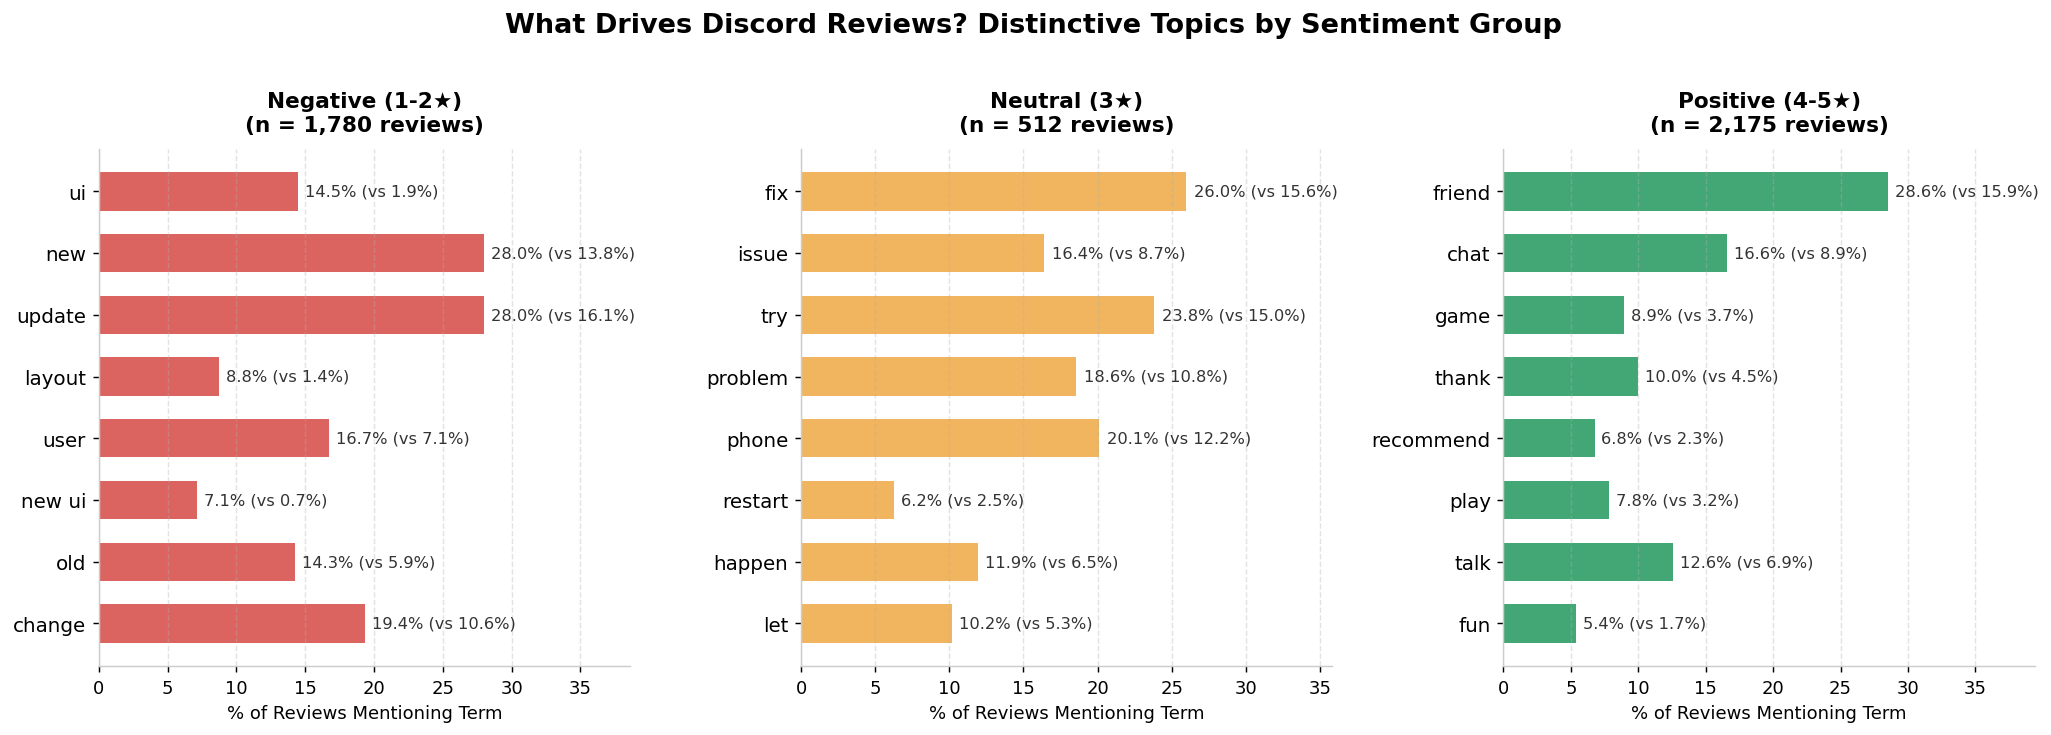

In [27]:
# =============================================================================
# CELL 23: VISUALIZATION - DISTINCTIVE TERMS BY SENTIMENT GROUP
# =============================================================================
import matplotlib.pyplot as plt

# Reuse the scored terms from Cell 23 instead of recomputing them
if "top_terms" not in globals():
    raise NameError("top_terms not found. Run Cell 23 first (with the top_terms lines added).")

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8

groups = ["Negative (1-2★)", "Neutral (3★)", "Positive (4-5★)"]
colors = ["#D9534F", "#F0AD4E", "#2E9E66"]  # Red, Amber, Green

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), dpi=130)
fig.suptitle(
    "What Drives Discord Reviews? Distinctive Topics by Sentiment Group",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)

for ax, g, color in zip(axes, groups, colors):
    # Top 8 terms; reverse so #1 sits at the top of the horizontal bars
    top8 = top_terms[g][:8][::-1]
    labels = [t[1] for t in top8]
    pct_in_g = [t[2] for t in top8]
    pct_other = [t[3] for t in top8]

    bars = ax.barh(labels, pct_in_g, color=color, alpha=0.9, height=0.62)
    ax.set_title(f"{g}\n(n = {group_sizes[g]:,} reviews)", fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("% of Reviews Mentioning Term", fontsize=10)
    ax.set_xlim(0, max(pct_in_g) * 1.38)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=11)

    for bar, p_g, p_o in zip(bars, pct_in_g, pct_other):
        ax.text(
            bar.get_width() + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{p_g:.1f}% (vs {p_o:.1f}%)",
            va="center", ha="left", fontsize=9, color="#333333",
        )

plt.tight_layout()
plt.show()

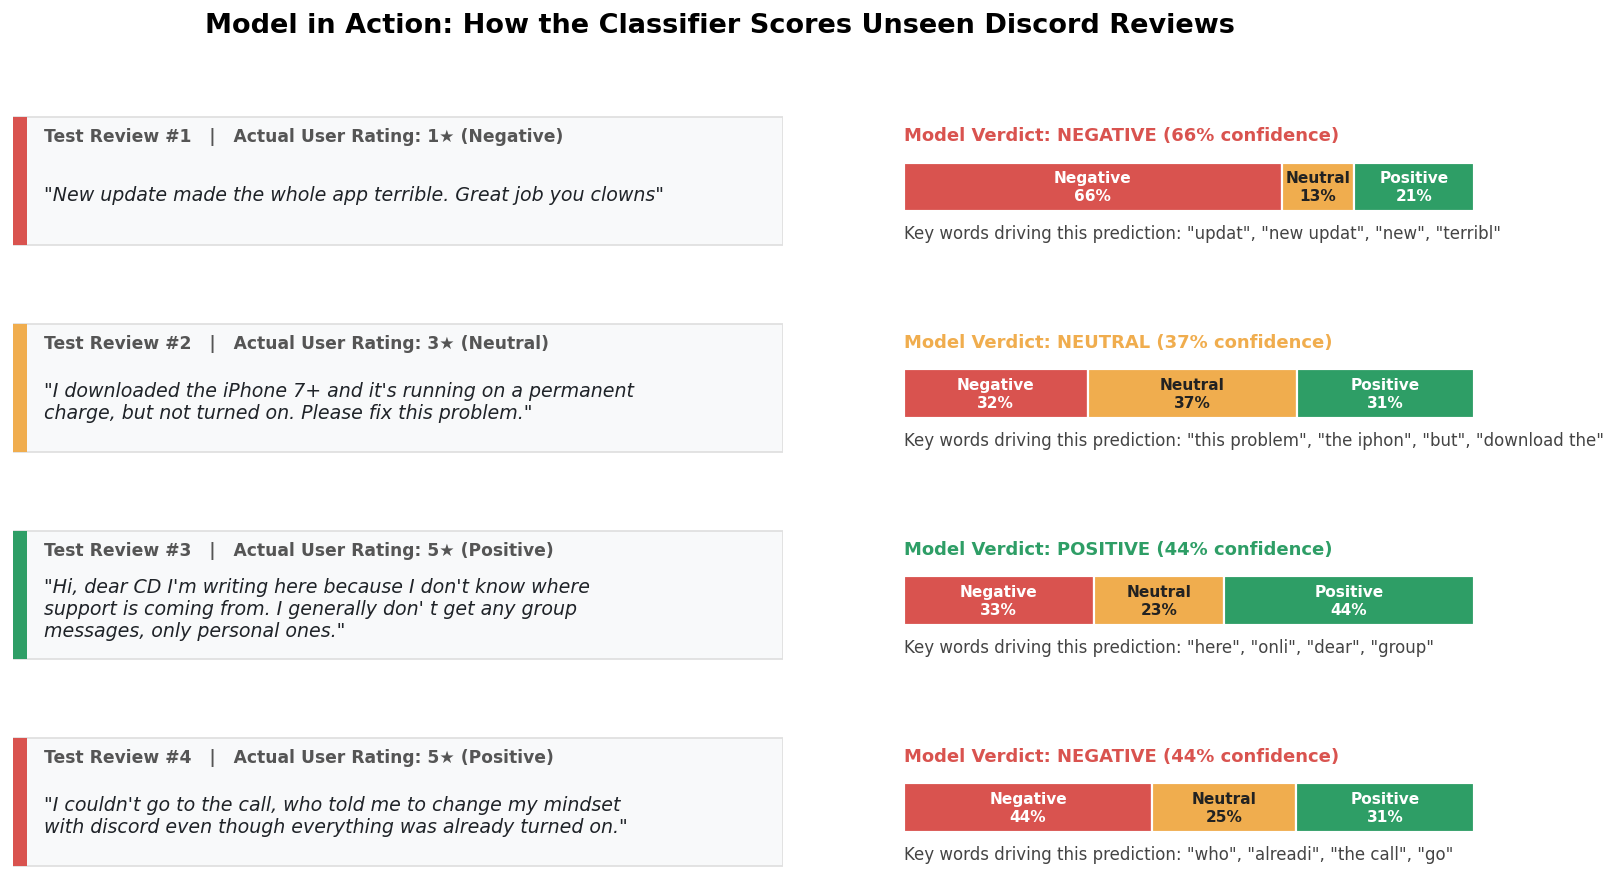

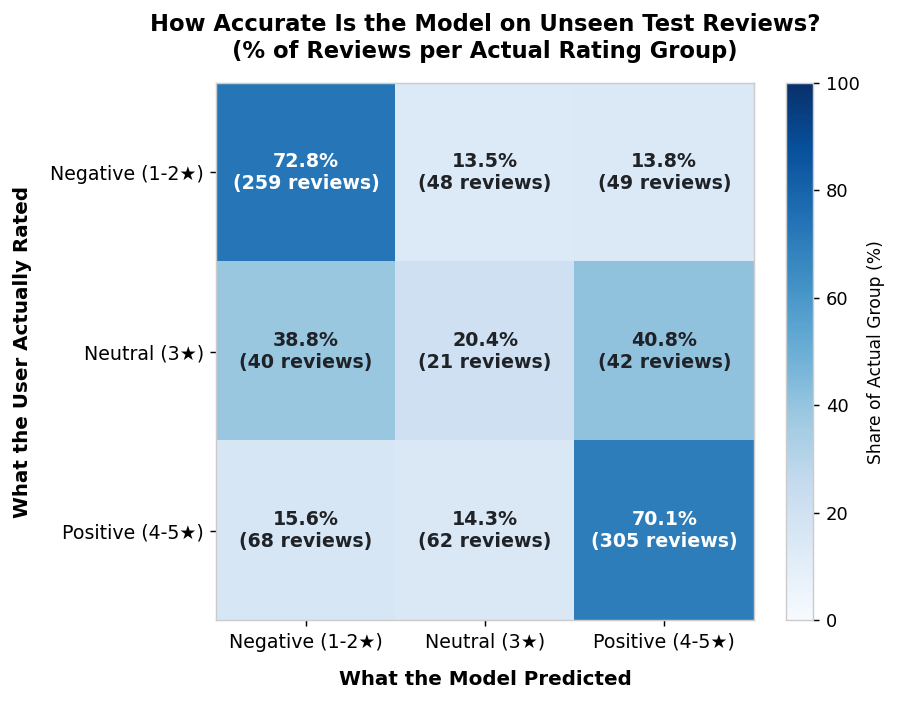

In [28]:
# =============================================================================
# CELL 24: "MODEL IN ACTION" VISUALS (LIVE REVIEW SCANNER & ACCURACY HEATMAP)
# =============================================================================
import re
import textwrap
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# 1. Use the 3-class model trained in Cell 22
if "clf_3c" not in globals() or "vec_3c" not in globals():
    raise NameError("No trained classifier found. Run Cell 22 first.")
assert "preprocess_text" in globals(), "Run Cell 15 first (defines preprocess_text)."

active_clf = clf_3c
active_vec = vec_3c
class_names = ["Negative (1-2★)", "Neutral (3★)", "Positive (4-5★)"]
short_names = ["Negative", "Neutral", "Positive"]
palette = ["#D9534F", "#F0AD4E", "#2E9E66"]
X_eval_tfidf = X_test_tfidf_3c
y_eval = y_test_3c
test_indices = X_test_3c.index
source_df = df_3c

feature_names = active_vec.get_feature_names_out()

def explain_single_review(raw_text: str):
    """Runs one review through preprocessing, TF-IDF, and Logistic Regression,
    returning class probabilities and the top words driving the prediction."""
    proc = preprocess_text(raw_text)
    vec_row = active_vec.transform([proc])
    probs = active_clf.predict_proba(vec_row)[0]
    pred_idx = int(np.argmax(probs))

    # Extract per-token contribution (TF-IDF weight * model coefficient for predicted class)
    coefs = active_clf.coef_[pred_idx]

    nonzero_cols = vec_row.nonzero()[1]
    contributions = [
        (vec_row[0, col] * coefs[col], feature_names[col])
        for col in nonzero_cols
    ]
    contributions.sort(reverse=True)
    top_triggers = [tok for score, tok in contributions if score > 0][:4]
    return probs, pred_idx, top_triggers

# 2. Pick 4 readable, real unseen reviews from the test split across sentiment tiers
demo_samples = []
if "content" in source_df.columns:
    test_subset = source_df.loc[test_indices].copy()
    test_subset["true_label"] = y_eval
    test_subset["clean_len"] = test_subset["content"].astype(str).str.strip().str.len()
    # Select concise reviews (45–160 chars) so quotes fit cleanly on the visual card
    readable = test_subset[(test_subset["clean_len"] >= 45) & (test_subset["clean_len"] <= 160)]

    target_sequence = [0, 1, 2, 2]
    used_idx = set()

    for idx_num, target_cls in enumerate(target_sequence):
        candidates = readable[(readable["true_label"] == target_cls) & (~readable.index.isin(used_idx))]
        for row_idx, row in candidates.iterrows():
            probs, pred_idx, triggers = explain_single_review(str(row["content"]))
            # Show 3 accurate predictions + 1 nuanced/borderline case for realism
            want_match = idx_num < 3
            if (pred_idx == target_cls) == want_match and len(triggers) >= 2:
                used_idx.add(row_idx)
                rating_val = int(row["im:rating_num"]) if "im:rating_num" in row and pd.notna(row["im:rating_num"]) else "?"
                demo_samples.append({
                    "quote": re.sub(r"\s+", " ", str(row["content"])).strip(),
                    "actual": f"{rating_val}★ ({short_names[target_cls]})",
                    "probs": probs,
                    "pred_idx": pred_idx,
                    "triggers": triggers,
                })
                break

# Fallback samples if fewer than 4 suitable test reviews were found
if len(demo_samples) < 4:
    fallback_texts = [
        ("The new mobile UI layout is confusing and hard to navigate, please revert it.", "1★ (Negative)"),
        ("Great app for talking with friends, but notifications keep glitching on my phone.", "3★ (Neutral)"),
        ("Best app to chat and play games with my friends every single day!", "5★ (Positive)"),
        ("Love the voice chat quality when gaming, though the latest update feels slower.", "4★ (Positive)"),
    ]
    demo_samples = []
    for txt, act in fallback_texts:
        probs, pred_idx, triggers = explain_single_review(txt)
        demo_samples.append({
            "quote": txt,
            "actual": act,
            "probs": probs,
            "pred_idx": pred_idx,
            "triggers": triggers,
        })

# -----------------------------------------------------------------------------
# FIGURE 1: Live Review Scanner (Input Text -> Predicted Probabilities & Triggers)
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(14.5, 7.6), dpi=130)
gs = gridspec.GridSpec(len(demo_samples), 2, width_ratios=[1.35, 1.0], hspace=0.48, wspace=0.18)

fig.suptitle(
    "Model in Action: How the Classifier Scores Unseen Discord Reviews",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)

for row_i, item in enumerate(demo_samples):
    pred_idx = item["pred_idx"]
    pred_color = palette[pred_idx]
    probs = item["probs"] * 100

    # Left Card: Actual Review Quote + Ground-Truth Rating
    ax_txt = fig.add_subplot(gs[row_i, 0])
    ax_txt.set_xlim(0, 1)
    ax_txt.set_ylim(0, 1)
    ax_txt.axis("off")

    # Subtle background card + colored left border bar
    ax_txt.add_patch(plt.Rectangle((0, 0.04), 1, 0.92, facecolor="#F8F9FA", edgecolor="#E0E0E0", lw=1))
    ax_txt.add_patch(plt.Rectangle((0, 0.04), 0.018, 0.92, facecolor=pred_color, edgecolor="none"))

    short_quote = textwrap.shorten(item["quote"], width=165, placeholder="...")
    wrapped_quote = textwrap.fill(f'"{short_quote}"', width=62)

    ax_txt.text(
        0.04, 0.82,
        f"Test Review #{row_i + 1}   |   Actual User Rating: {item['actual']}",
        fontsize=9.5, fontweight="bold", color="#555555", va="center",
    )
    ax_txt.text(
        0.04, 0.40,
        wrapped_quote,
        fontsize=10.5, color="#1F2328", va="center", style="italic",
    )

    # Right Panel: Stacked Confidence Bar + Key Trigger Words
    ax_bar = fig.add_subplot(gs[row_i, 1])
    left_cum = 0.0
    for p_val, c_hex, c_name in zip(probs, palette, short_names):
        ax_bar.barh([0], [p_val], left=left_cum, color=c_hex, height=0.42, edgecolor="white", linewidth=1.2)
        if p_val >= 11:
            txt_color = "#222222" if c_hex == "#F0AD4E" else "white"
            ax_bar.text(
                left_cum + p_val / 2, 0,
                f"{c_name}\n{p_val:.0f}%",
                ha="center", va="center", color=txt_color, fontsize=8.5, fontweight="bold",
            )
        left_cum += p_val

    ax_bar.set_xlim(0, 100)
    ax_bar.set_ylim(-0.55, 0.65)
    ax_bar.axis("off")

    ax_bar.text(
        0, 0.44,
        f"Model Verdict: {short_names[pred_idx].upper()} ({probs[pred_idx]:.0f}% confidence)",
        fontsize=10, fontweight="bold", color=pred_color, va="center",
    )
    trigger_str = ", ".join(f'"{t}"' for t in item["triggers"]) if item["triggers"] else "general phrasing"
    ax_bar.text(
        0, -0.40,
        f"Key words driving this prediction: {trigger_str}",
        fontsize=9.2, color="#444444", va="center",
    )

plt.show()

# -----------------------------------------------------------------------------
# FIGURE 2: Plain-English Model Accuracy Heatmap (Row-Normalized Confusion Matrix)
# -----------------------------------------------------------------------------
y_pred_eval = active_clf.predict(X_eval_tfidf)
cm_raw = confusion_matrix(y_eval, y_pred_eval)
cm_pct = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True) * 100

fig2, ax2 = plt.subplots(figsize=(7.5, 5.5), dpi=130)
im = ax2.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)

ax2.set_xticks(np.arange(len(class_names)))
ax2.set_yticks(np.arange(len(class_names)))
ax2.set_xticklabels(class_names, fontsize=10.5)
ax2.set_yticklabels(class_names, fontsize=10.5)
ax2.set_xlabel("What the Model Predicted", fontsize=11, fontweight="bold", labelpad=10)
ax2.set_ylabel("What the User Actually Rated", fontsize=11, fontweight="bold", labelpad=10)
ax2.set_title(
    "How Accurate Is the Model on Unseen Test Reviews?\n(% of Reviews per Actual Rating Group)",
    fontsize=12.5,
    fontweight="bold",
    pad=14,
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        pct_val = cm_pct[i, j]
        cnt_val = cm_raw[i, j]
        text_color = "white" if pct_val > 52 else "#1F2328"
        ax2.text(
            j, i,
            f"{pct_val:.1f}%\n({cnt_val:,} reviews)",
            ha="center", va="center", color=text_color, fontsize=10.5, fontweight="bold",
        )

cbar = plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label("Share of Actual Group (%)", fontsize=9.5)

plt.tight_layout()
plt.show()

# Concluding Text Analysis

User sentiment in Discord’s iOS App Store reviews drops noticeably after major version updates, mostly because of frustrating UX changes rather than actual app outages. Even without exact release timestamps in the dataset, word patterns make it clear that negative reviews (1-2★, $n = 1,780$) focus heavily on UI backlash, led by update (28.0% vs. 16.1% in other groups), new (28.0% vs. 13.8%), and ui (14.5% vs. 1.9%). On the flip side, positive reviews (4-5★, $n = 2,175$) highlight everyday social features like friend (28.6%) and chat (16.6%).

The machine learning results also show that user experience matters much more than regional differences. A text-only TF-IDF model hits 81.54% binary accuracy (0.8877 ROC-AUC), while regional English proficiency (ef_score) barely beats random guessing at 54.99% and adds -0.13% lift. Bringing neutral 3★ reviews ($n = 512$) into a 3-class model lowers accuracy to 65.44% (with just 20.4% neutral recall), largely because mid-tier bug complaints (fix at 26.0%) blend into the more polarized ratings. Pairing future NLP models with exact App Store release dates would make it even easier to pinpoint these post-update UX dips.